In [2]:
import sys, datetime, calendar
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from market_analysis.config import (
    PRODUCTS, FRONT_N, HORIZONS, HORIZON_BARS, OUTPUT_DIR,
    COMPRESSION as COMP_CFG, COMPRESSION_ATR as ATR_CFG,
)
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.signals.compression.calculate_multiday import build_scored_candles
from market_analysis.signals.compression.label_atr import label_compression_atr
from market_analysis.utils.metrics import threshold_sweep, pr_auc
from market_analysis.utils.plotting import styled_sweep_table
print("Imports OK")

Imports OK


In [3]:
def _months_back_start(months):
    t = datetime.date.today(); y, m = t.year, t.month - months
    while m <= 0: m += 12; y -= 1
    return datetime.date(y, m, min(t.day, calendar.monthrange(y, m)[1])).strftime("%Y-%m-%d")


_GROUPS = [("SUCCESS", "seagreen"), ("FAILURE", "tomato"), ("CONTINUATION", "goldenrod")]


def _dist_fig(df, title, ref):
    bins = np.arange(0, 1.05, 0.05)
    fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
    for ax, (o, c) in zip(axes[:3], _GROUPS):
        x = df.loc[df["outcome"] == o, "compression_score"]
        ax.hist(x, bins=bins, color=c, edgecolor="white", alpha=0.85)
        ax.axvline(ref, color="red", ls="--", lw=1.4, label=f"ref={ref:.2f}")
        ax.set_title(f"{o}  n={len(x)}", fontweight="bold")
        ax.set_xlim(0, 1); ax.set_xlabel("compression_score"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax = axes[3]
    for o, c in _GROUPS[:2]:
        x = df.loc[df["outcome"] == o, "compression_score"]
        if len(x):
            ax.hist(x, bins=bins, color=c, edgecolor="white", alpha=0.55,
                    density=True, label=f"{o} n={len(x)}")
    ax.axvline(ref, color="red", ls="--", lw=1.4)
    ax.set_title("Overlay (density)", fontweight="bold"); ax.set_xlim(0, 1)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=10, y=1.04); plt.tight_layout()
    return fig


def _bucket_table(df):
    d = df[df["outcome"].isin(["SUCCESS", "FAILURE", "CONTINUATION"])].copy()
    d["bucket"] = pd.cut(d["compression_score"], np.round(np.arange(0, 1.0501, 0.05), 2),
                         include_lowest=True, right=False)
    ct = (pd.crosstab(d["bucket"], d["outcome"], dropna=False)
            .reindex(columns=["SUCCESS", "FAILURE", "CONTINUATION"], fill_value=0))
    ct["N"] = ct.sum(axis=1)
    ct["success_rate"] = ct["SUCCESS"] / (ct["SUCCESS"] + ct["FAILURE"]).replace(0, np.nan)
    return ct


def _report(df, title, sweep_cfg, show_plots):
    vc = df["outcome"].value_counts()
    n_s, n_f = vc.get("SUCCESS", 0), vc.get("FAILURE", 0)
    br = n_s / (n_s + n_f) if (n_s + n_f) else float("nan")
    print(f"\n{'='*78}\n  {title}\n{'='*78}")
    print("  " + "  ".join(f"{k}={v}" for k, v in vc.items()) + f"   | base rate (S/(S+F)) = {br:.3f}")
    if df["success"].notna().sum() == 0:
        print("  [no valid labelled rows]"); return
    print("\n  Score-bucket distribution (0 -> 1):")
    display(_bucket_table(df).style.format({"success_rate": "{:.2f}"}, na_rep="--"))
    tbl, base = threshold_sweep(df, "compression_score", "success", cfg=sweep_cfg)
    print(f"\n  Threshold sweep  | base={base:.3f}  PR-AUC={pr_auc(df, 'compression_score', 'success'):.3f}")
    display(styled_sweep_table(tbl, title))
    if show_plots:
        fig = _dist_fig(df, title, COMP_CFG.get("threshold_line", 0.40))
        plt.show(); plt.close(fig)
    return tbl, base


def run_compression_atr_analysis(
    product_code,
    horizons=None,                 # e.g. ["1d","2d","3d","5d"]
    tracks=("candle", "custom"),   # A = candle-as-day, B = non-overlapping n-day baseline
    months_back=9,
    front_n=FRONT_N,
    k_atr=None, forward_days=None, label_atr_period=None, continuation_mode=None,
    grid_step=0.05,
    per_instrument_tables=False,   # True = also show sweep per instrument
    show_plots=True,
    save_outputs=False,
):
    horizons = horizons or HORIZONS
    k_atr    = ATR_CFG["k_atr"]               if k_atr is None else k_atr
    fwd      = ATR_CFG["forward_days"]        if forward_days is None else forward_days
    atr_p    = ATR_CFG["label_atr_period"]    if label_atr_period is None else label_atr_period
    cmode    = ATR_CFG["continuation_mode"]   if continuation_mode is None else continuation_mode

    sweep_cfg = dict(
        threshold_grid_start=0.0, threshold_grid_stop=1.0 + grid_step / 2,
        threshold_grid_step=grid_step,
        min_signal_count=ATR_CFG["min_signal_count"], n_bootstrap=ATR_CFG["n_bootstrap"],
        random_seed=ATR_CFG["random_seed"], forward_days=fwd,
    )

    start, end = _months_back_start(months_back), datetime.date.today().strftime("%Y-%m-%d")
    by_struct  = get_all_front_instruments(product_code, front_n=front_n)

    # ---- fetch 1D once per instrument ----
    raw = {}
    for struct, instrs in by_struct.items():
        for ins in instrs:
            df = fetch_ohlc_1d(ins, product_code, getData_OHLC_v2, start, end)
            if df is None or len(df) < 30:
                print(f"[SKIP] {ins}: {0 if df is None else len(df)} bars"); continue
            raw[(struct, ins)] = df
    print(f"Fetched {len(raw)} instruments | k_atr={k_atr}  fwd={fwd}d  ATR period={atr_p}  "
          f"continuation={cmode}")

    summary, out = [], {"labeled": {}, "sweeps": {}}

    for track in tracks:
        for horizon in horizons:
            n = HORIZON_BARS[horizon]
            if track == "custom" and n == 1:
                continue                               # identical to track A for 1d
            for struct in by_struct:
                parts = []
                for (s, ins), df1d in raw.items():
                    if s != struct:
                        continue
                    try:
                        scored = build_scored_candles(
                            df1d, n, track=track,
                            range_baseline=COMP_CFG["range_baseline"], atr_period=COMP_CFG["atr_period"],
                            rv_period=COMP_CFG["rv_period"], persistence_window=COMP_CFG["persistence_window"],
                            compression_threshold=COMP_CFG["compression_threshold"],
                            label_atr_period=atr_p)
                        if scored.empty:
                            continue
                        lab = label_compression_atr(
                            scored, k_atr=k_atr, forward_days=fwd,
                            compression_threshold=COMP_CFG["compression_threshold"],
                            continuation_threshold=ATR_CFG["continuation_threshold"],
                            continuation_lookahead=ATR_CFG["continuation_lookahead"],
                            continuation_mode=cmode)
                    except Exception as e:
                        print(f"[WARN] {ins} {horizon} {track}: {e}"); continue
                    if lab.empty:
                        continue
                    lab["instrument"], lab["structure"] = ins, struct
                    lab["horizon"], lab["track"] = horizon, track
                    parts.append(lab)

                    vc = lab["outcome"].value_counts()
                    s_, f_ = vc.get("SUCCESS", 0), vc.get("FAILURE", 0)
                    summary.append(dict(track=track, horizon=horizon, structure=struct, instrument=ins,
                                        signals=len(lab), success=s_, failure=f_,
                                        continuation=vc.get("CONTINUATION", 0),
                                        censored=vc.get("CENSORED", 0),
                                        base_rate=s_ / (s_ + f_) if (s_ + f_) else np.nan))
                    if per_instrument_tables and (s_ + f_):
                        t, b = threshold_sweep(lab, "compression_score", "success", cfg=sweep_cfg)
                        display(styled_sweep_table(t, f"{ins} | {horizon} | {track} | base={b:.3f}"))

                if not parts:
                    continue
                pooled = pd.concat(parts, ignore_index=True)
                key = (track, horizon, struct)
                out["labeled"][key] = pooled
                title = (f"{struct.upper()} pooled | {horizon} | track={'A candle-as-day' if track=='candle' else 'B custom n-day baseline'} "
                         f"| success: move > {k_atr}×ATR in {fwd}d")
                res = _report(pooled, title, sweep_cfg, show_plots)
                if res: out["sweeps"][key] = res
                if save_outputs:
                    d = OUTPUT_DIR / product_code.lower() / "compression_atr" / track
                    d.mkdir(parents=True, exist_ok=True)
                    pooled.to_csv(d / f"{struct}_{horizon}_labeled.csv", index=False, encoding="utf-8-sig")
                    if res: res[0].to_csv(d / f"{struct}_{horizon}_sweep.csv", index=False, encoding="utf-8-sig")

    out["summary"] = pd.DataFrame(summary)
    print("\n" + "#" * 78 + "\n  PER-INSTRUMENT SUMMARY\n" + "#" * 78)
    display(out["summary"])
    return out

Fetched 10 instruments | k_atr=1.0  fwd=10d  ATR period=10  continuation=exclude

  SPREAD pooled | 1d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  SUCCESS=73  CONTINUATION=34  CENSORED=31  FAILURE=9   | base rate (S/(S+F)) = 0.890

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",2,0,0,2,1.00
"[0.2, 0.25)",3,0,1,4,1.00
"[0.25, 0.3)",6,1,1,8,0.86
"[0.3, 0.35)",9,1,5,15,0.90
"[0.35, 0.4)",11,3,5,19,0.79
"[0.4, 0.45)",10,0,5,15,1.00



  Threshold sweep  | base=0.890  PR-AUC=0.873


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,82,0.890,"[0.829, 0.945]",1.000,0.942,—,1.000,73,9,0,0,False
1,0.050,82,0.890,"[0.829, 0.945]",1.000,0.942,—,1.000,73,9,0,0,False
2,0.100,82,0.890,"[0.829, 0.945]",1.000,0.942,—,1.000,73,9,0,0,False
3,0.150,82,0.890,"[0.829, 0.945]",1.000,0.942,—,1.000,73,9,0,0,False
4,0.200,80,0.887,"[0.827, 0.943]",0.973,0.928,-0.056,0.997,71,9,2,0,False
5,0.250,77,0.883,"[0.818, 0.941]",0.932,0.907,-0.089,0.992,68,9,5,0,False
6,0.300,70,0.886,"[0.828, 0.944]",0.849,0.867,-0.035,0.995,62,8,11,1,False
7,0.350,60,0.883,"[0.811, 0.952]",0.726,0.797,-0.037,0.992,53,7,20,2,False
8,0.400,46,0.913,"[0.866, 0.979]",0.575,0.706,0.082,1.026,42,4,31,5,False
9,0.450,36,0.889,"[0.835, 0.974]",0.438,0.587,-0.004,0.998,32,4,41,5,False


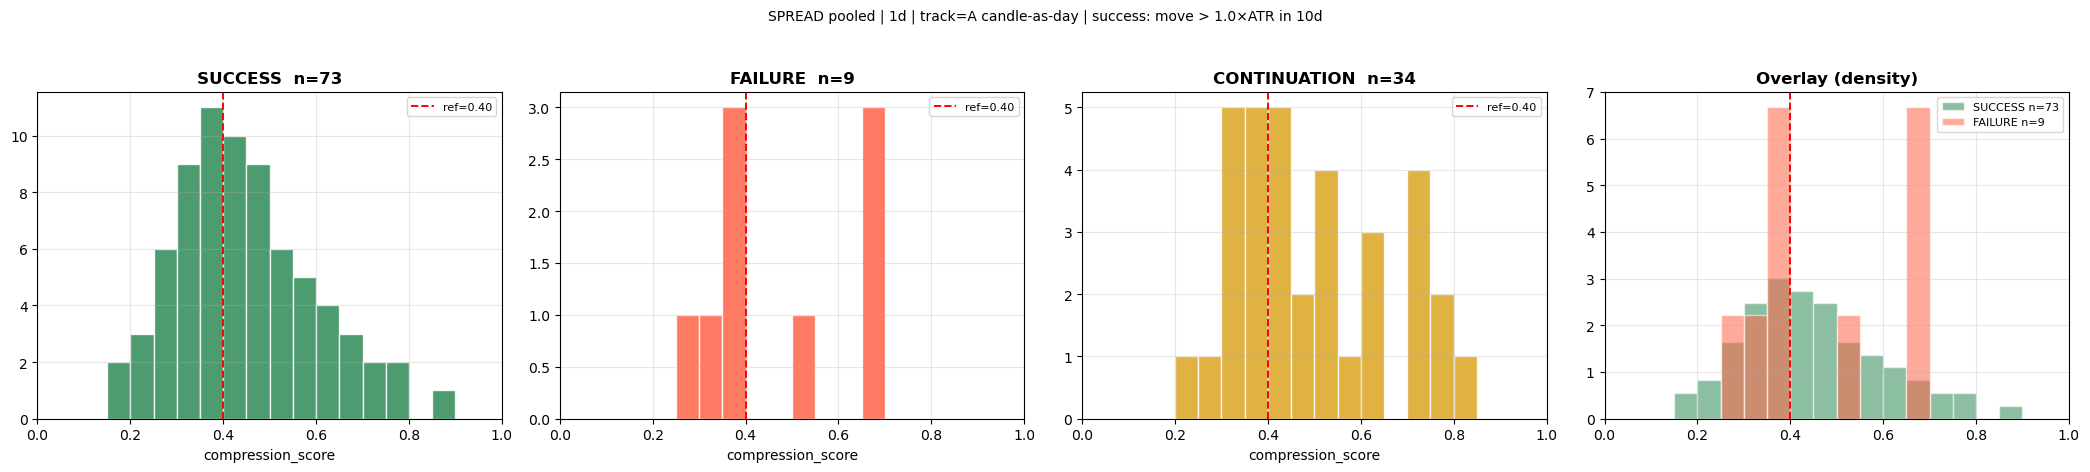


  JUMBO pooled | 1d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  SUCCESS=57  CONTINUATION=25  CENSORED=24  FAILURE=3   | base rate (S/(S+F)) = 0.950

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",2,1,4,7,0.67
"[0.25, 0.3)",7,0,2,9,1.00
"[0.3, 0.35)",6,1,2,9,0.86
"[0.35, 0.4)",9,0,2,11,1.00
"[0.4, 0.45)",6,0,5,11,1.00



  Threshold sweep  | base=0.950  PR-AUC=0.976


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,60,0.950,"[0.917, 1.000]",1.000,0.974,—,1.000,57,3,0,0,False
1,0.050,60,0.950,"[0.917, 1.000]",1.000,0.974,—,1.000,57,3,0,0,False
2,0.100,60,0.950,"[0.917, 1.000]",1.000,0.974,—,1.000,57,3,0,0,False
3,0.150,60,0.950,"[0.917, 1.000]",1.000,0.974,—,1.000,57,3,0,0,False
4,0.200,60,0.950,"[0.917, 1.000]",1.000,0.974,—,1.000,57,3,0,0,False
5,0.250,57,0.965,"[0.944, 1.000]",0.965,0.965,0.298,1.016,55,2,2,1,False
6,0.300,50,0.960,"[0.933, 1.000]",0.842,0.897,0.103,1.011,48,2,9,1,False
7,0.350,43,0.977,"[0.951, 1.000]",0.737,0.840,0.195,1.028,42,1,15,2,False
8,0.400,34,0.971,"[0.935, 1.000]",0.579,0.725,0.108,1.022,33,1,24,2,False
9,0.450,28,0.964,"[0.918, 1.000]",0.474,0.635,0.061,1.015,27,1,30,2,False


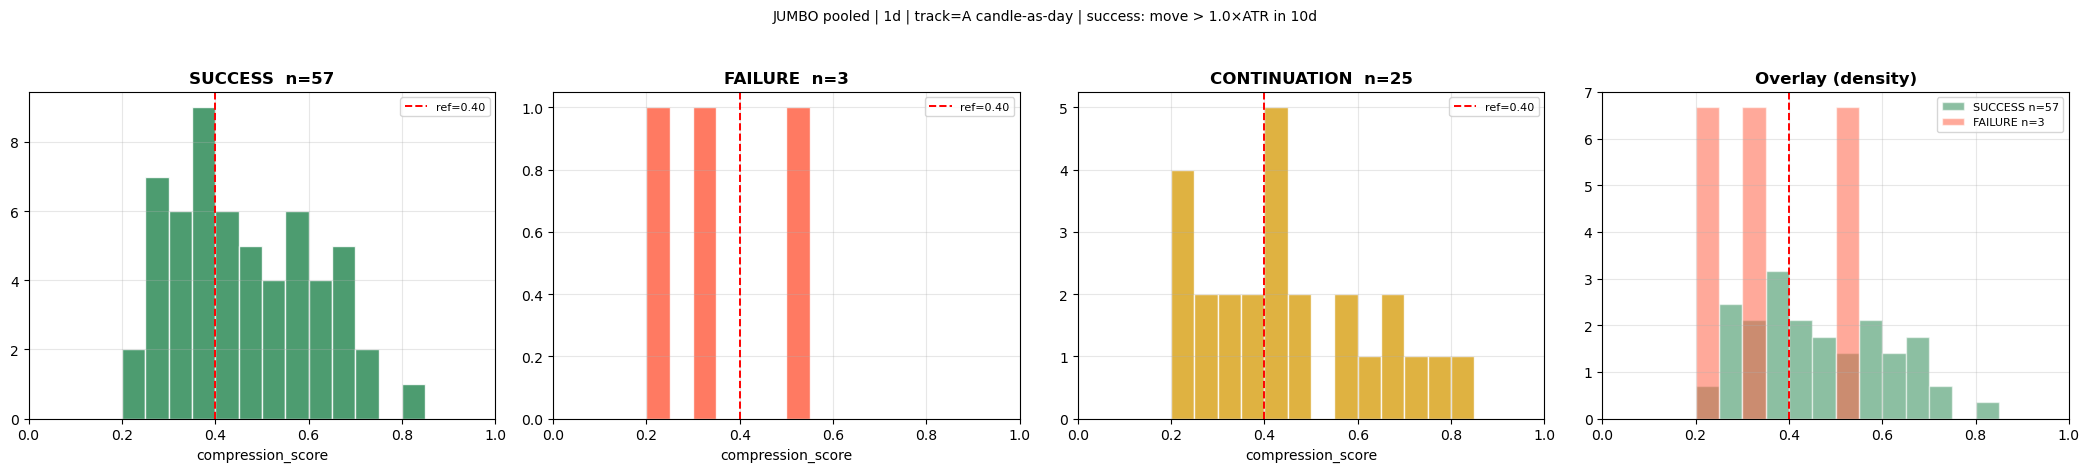


  SPREAD pooled | 2d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=56  SUCCESS=54  CENSORED=33  FAILURE=14   | base rate (S/(S+F)) = 0.794

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",5,1,2,8,0.83
"[0.25, 0.3)",4,0,1,5,1.00
"[0.3, 0.35)",3,0,2,5,1.00
"[0.35, 0.4)",9,1,2,12,0.90
"[0.4, 0.45)",7,3,7,17,0.70



  Threshold sweep  | base=0.794  PR-AUC=0.723


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,68,0.794,"[0.765, 0.882]",1.000,0.885,—,1.000,54,14,0,0,False
1,0.050,68,0.794,"[0.765, 0.882]",1.000,0.885,—,1.000,54,14,0,0,False
2,0.100,68,0.794,"[0.765, 0.882]",1.000,0.885,—,1.000,54,14,0,0,False
3,0.150,68,0.794,"[0.765, 0.882]",1.000,0.885,—,1.000,54,14,0,0,False
4,0.200,68,0.794,"[0.765, 0.882]",1.000,0.885,—,1.000,54,14,0,0,False
5,0.250,62,0.790,"[0.748, 0.879]",0.907,0.845,-0.030,0.995,49,13,5,1,False
6,0.300,58,0.776,"[0.722, 0.874]",0.833,0.804,-0.109,0.977,45,13,9,1,False
7,0.350,55,0.764,"[0.716, 0.860]",0.778,0.771,-0.155,0.962,42,13,12,1,False
8,0.400,45,0.733,"[0.667, 0.835]",0.611,0.667,-0.210,0.923,33,12,21,2,False
9,0.450,35,0.743,"[0.608, 0.862]",0.481,0.584,-0.131,0.935,26,9,28,5,False


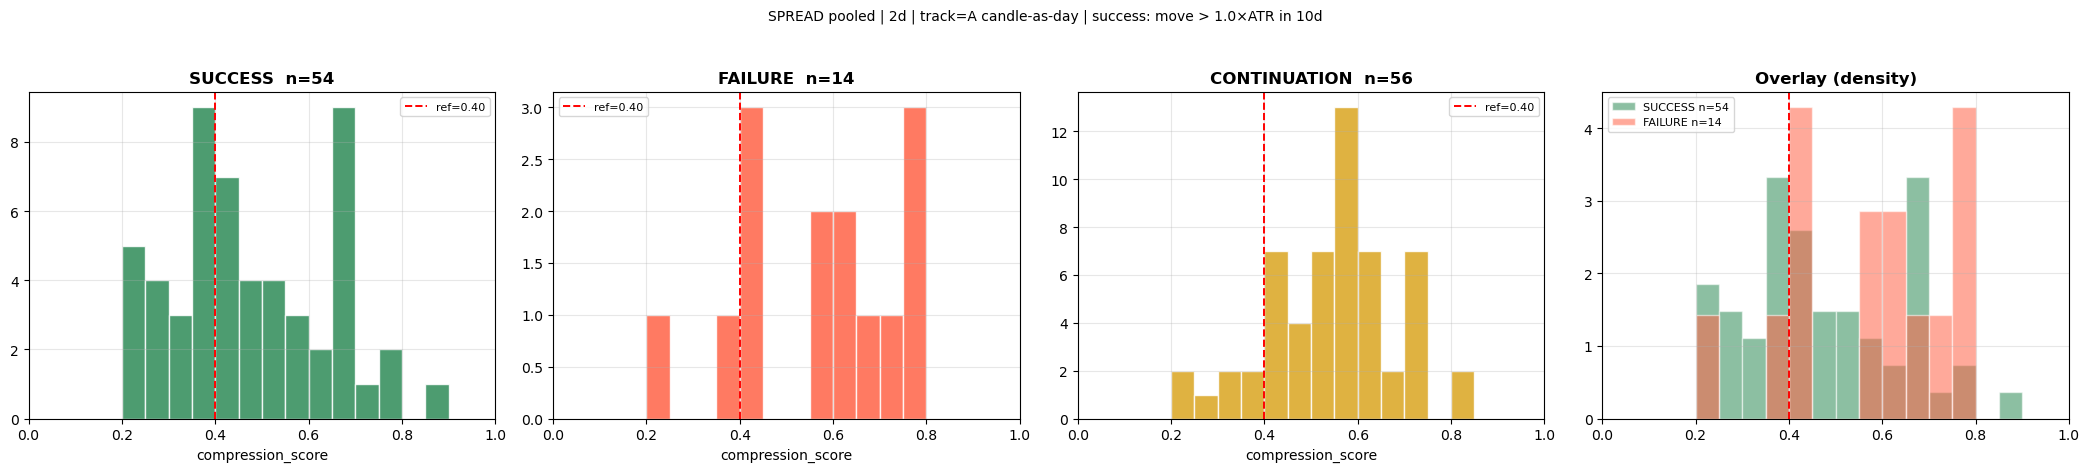


  JUMBO pooled | 2d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=50  SUCCESS=46  CENSORED=23  FAILURE=11   | base rate (S/(S+F)) = 0.807

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",3,2,1,6,0.60
"[0.25, 0.3)",3,1,1,5,0.75
"[0.3, 0.35)",5,1,2,8,0.83
"[0.35, 0.4)",6,2,4,12,0.75
"[0.4, 0.45)",3,0,2,5,1.00



  Threshold sweep  | base=0.807  PR-AUC=0.805


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,57,0.807,"[0.772, 0.912]",1.000,0.893,—,1.000,46,11,0,0,False
1,0.050,57,0.807,"[0.772, 0.912]",1.000,0.893,—,1.000,46,11,0,0,False
2,0.100,57,0.807,"[0.772, 0.912]",1.000,0.893,—,1.000,46,11,0,0,False
3,0.150,57,0.807,"[0.772, 0.912]",1.000,0.893,—,1.000,46,11,0,0,False
4,0.200,57,0.807,"[0.772, 0.912]",1.000,0.893,—,1.000,46,11,0,0,False
5,0.250,52,0.827,"[0.780, 0.939]",0.935,0.878,0.163,1.025,43,9,3,2,False
6,0.300,48,0.833,"[0.776, 0.937]",0.870,0.851,0.154,1.033,40,8,6,3,False
7,0.350,42,0.833,"[0.756, 0.930]",0.761,0.795,0.112,1.033,35,7,11,4,False
8,0.400,34,0.853,"[0.774, 0.971]",0.630,0.725,0.141,1.057,29,5,17,6,False
9,0.450,31,0.839,"[0.750, 0.970]",0.565,0.675,0.088,1.039,26,5,20,6,False


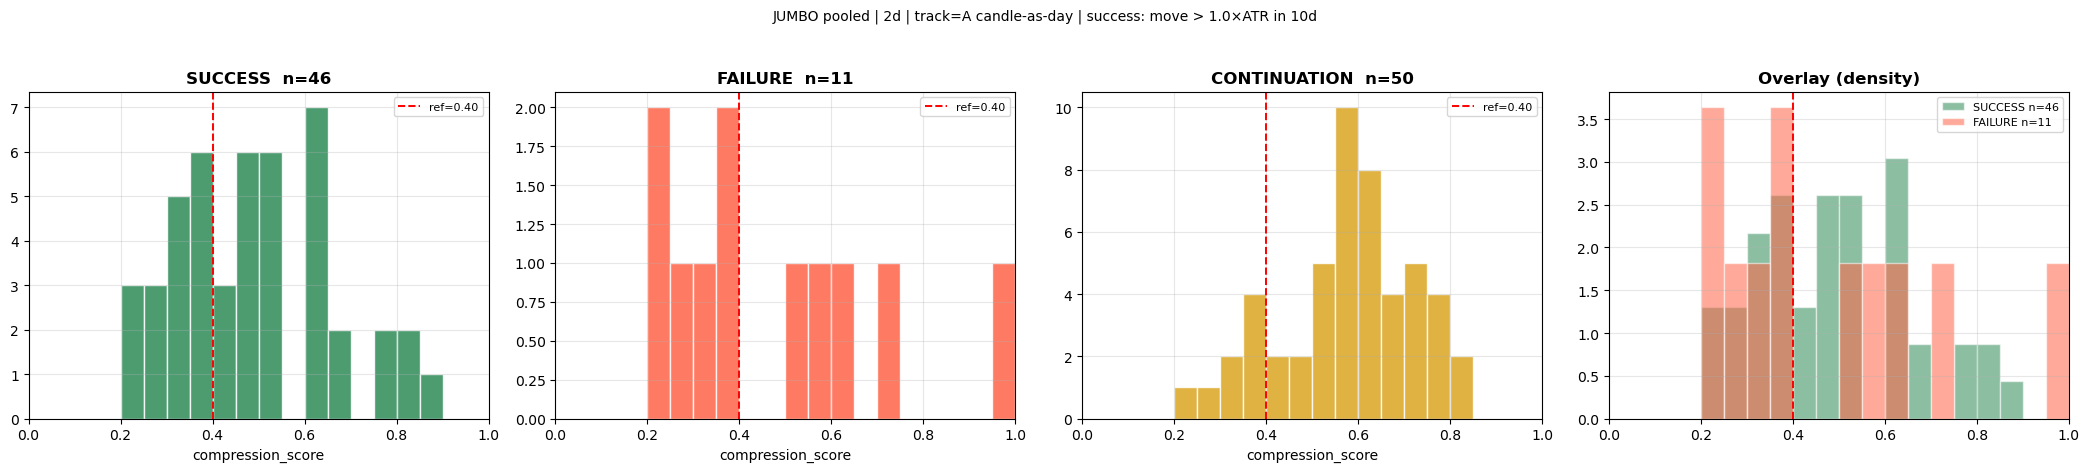


  SPREAD pooled | 3d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=78  CENSORED=38  SUCCESS=37  FAILURE=18   | base rate (S/(S+F)) = 0.673

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",1,0,0,1,1.00
"[0.2, 0.25)",3,1,3,7,0.75
"[0.25, 0.3)",2,1,2,5,0.67
"[0.3, 0.35)",6,7,4,17,0.46
"[0.35, 0.4)",5,0,6,11,1.00
"[0.4, 0.45)",3,2,5,10,0.60



  Threshold sweep  | base=0.673  PR-AUC=0.729


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,55,0.673,"[0.600, 0.782]",1.000,0.804,—,1.000,37,18,0,0,False
1,0.050,55,0.673,"[0.600, 0.782]",1.000,0.804,—,1.000,37,18,0,0,False
2,0.100,55,0.673,"[0.600, 0.782]",1.000,0.804,—,1.000,37,18,0,0,False
3,0.150,55,0.673,"[0.600, 0.782]",1.000,0.804,—,1.000,37,18,0,0,False
4,0.200,54,0.667,"[0.594, 0.778]",0.973,0.791,-0.095,0.991,36,18,1,0,False
5,0.250,50,0.660,"[0.571, 0.771]",0.892,0.759,-0.086,0.981,33,17,4,1,False
6,0.300,47,0.660,"[0.587, 0.759]",0.838,0.738,-0.068,0.980,31,16,6,2,False
7,0.350,34,0.735,"[0.648, 0.820]",0.676,0.704,0.170,1.093,25,9,12,9,False
8,0.400,29,0.690,"[0.603, 0.794]",0.541,0.606,0.038,1.025,20,9,17,9,False
9,0.450,24,0.708,"[0.600, 0.833]",0.459,0.557,0.067,1.053,17,7,20,11,False


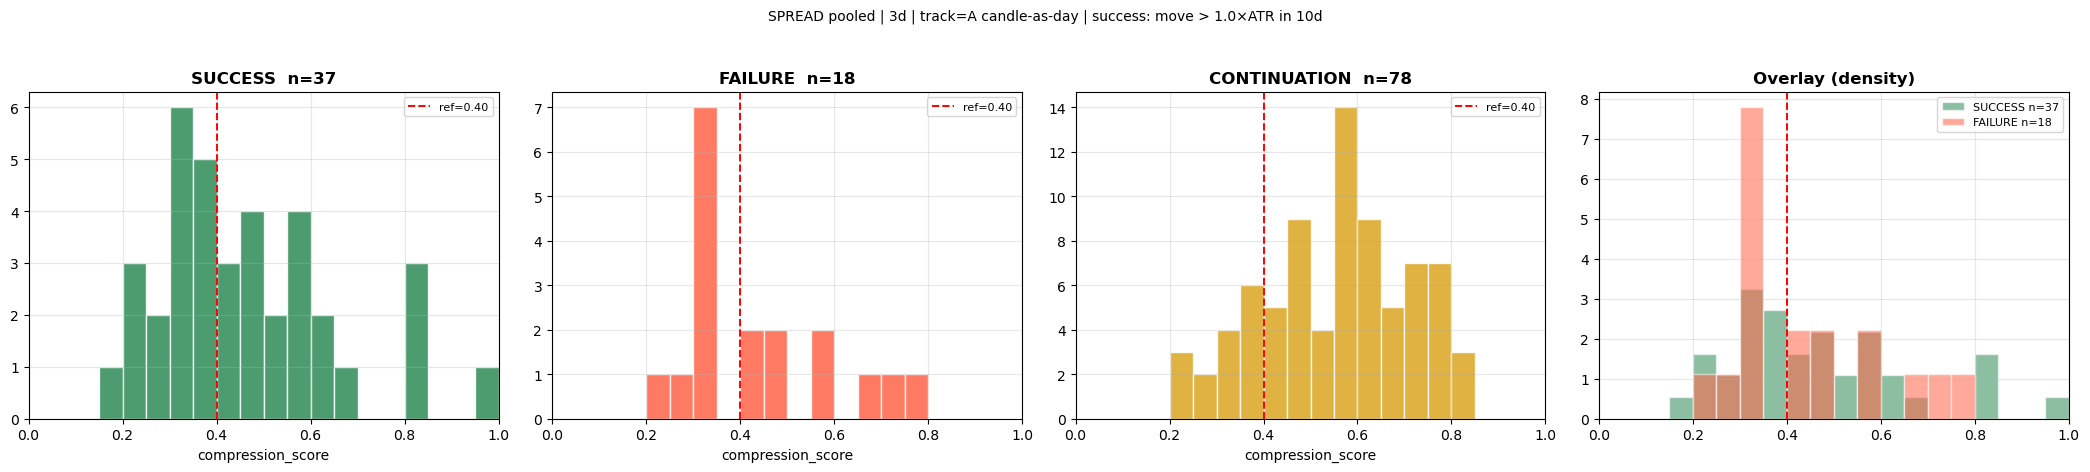


  JUMBO pooled | 3d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=67  SUCCESS=35  CENSORED=31  FAILURE=12   | base rate (S/(S+F)) = 0.745

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",2,0,0,2,1.00
"[0.2, 0.25)",2,0,1,3,1.00
"[0.25, 0.3)",3,1,3,7,0.75
"[0.3, 0.35)",6,2,2,10,0.75
"[0.35, 0.4)",4,1,4,9,0.80
"[0.4, 0.45)",1,0,7,8,1.00



  Threshold sweep  | base=0.745  PR-AUC=0.662


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,47,0.745,"[0.596, 0.936]",1.000,0.854,—,1.000,35,12,0,0,False
1,0.050,47,0.745,"[0.596, 0.936]",1.000,0.854,—,1.000,35,12,0,0,False
2,0.100,47,0.745,"[0.596, 0.936]",1.000,0.854,—,1.000,35,12,0,0,False
3,0.150,47,0.745,"[0.596, 0.936]",1.000,0.854,—,1.000,35,12,0,0,False
4,0.200,45,0.733,"[0.582, 0.933]",0.943,0.825,-0.123,0.985,33,12,2,0,False
5,0.250,43,0.721,"[0.551, 0.931]",0.886,0.795,-0.179,0.968,31,12,4,0,False
6,0.300,39,0.718,"[0.544, 0.927]",0.800,0.757,-0.135,0.964,28,11,7,1,False
7,0.350,31,0.710,"[0.517, 0.916]",0.629,0.667,-0.112,0.953,22,9,13,3,False
8,0.400,26,0.692,"[0.500, 0.900]",0.514,0.590,-0.134,0.930,18,8,17,4,False
9,0.450,25,0.680,"[0.475, 0.897]",0.486,0.567,-0.158,0.913,17,8,18,4,False


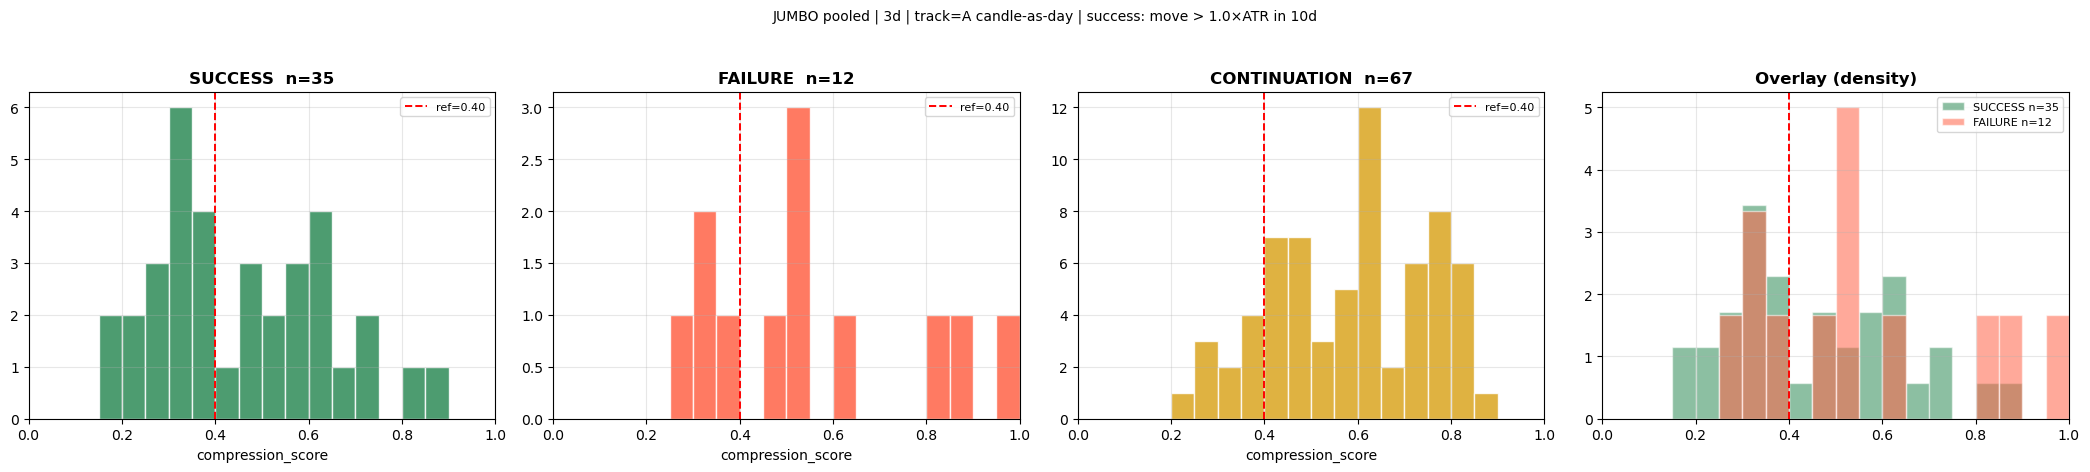


  SPREAD pooled | 5d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=92  CENSORED=37  FAILURE=35  SUCCESS=29   | base rate (S/(S+F)) = 0.453

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",1,0,0,1,1.00
"[0.2, 0.25)",2,10,2,14,0.17
"[0.25, 0.3)",4,4,2,10,0.50
"[0.3, 0.35)",6,4,8,18,0.60
"[0.35, 0.4)",2,4,8,14,0.33
"[0.4, 0.45)",4,4,14,22,0.50



  Threshold sweep  | base=0.453  PR-AUC=0.465


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,64,0.453,"[0.391, 0.578]",1.000,0.624,—,1.000,29,35,0,0,False
1,0.050,64,0.453,"[0.391, 0.578]",1.000,0.624,—,1.000,29,35,0,0,False
2,0.100,64,0.453,"[0.391, 0.578]",1.000,0.624,—,1.000,29,35,0,0,False
3,0.150,64,0.453,"[0.391, 0.578]",1.000,0.624,—,1.000,29,35,0,0,False
4,0.200,63,0.444,"[0.361, 0.578]",0.966,0.609,-0.138,0.981,28,35,1,0,False
5,0.250,51,0.510,"[0.429, 0.674]",0.897,0.650,0.226,1.125,26,25,3,10,False
6,0.300,43,0.512,"[0.432, 0.663]",0.759,0.611,0.168,1.129,22,21,7,14,False
7,0.350,33,0.485,"[0.344, 0.677]",0.552,0.516,0.066,1.070,16,17,13,18,False
8,0.400,27,0.519,"[0.344, 0.704]",0.483,0.500,0.112,1.144,14,13,15,22,False
9,0.450,19,0.526,"[0.298, 0.750]",0.345,0.417,0.096,1.162,10,9,19,26,False


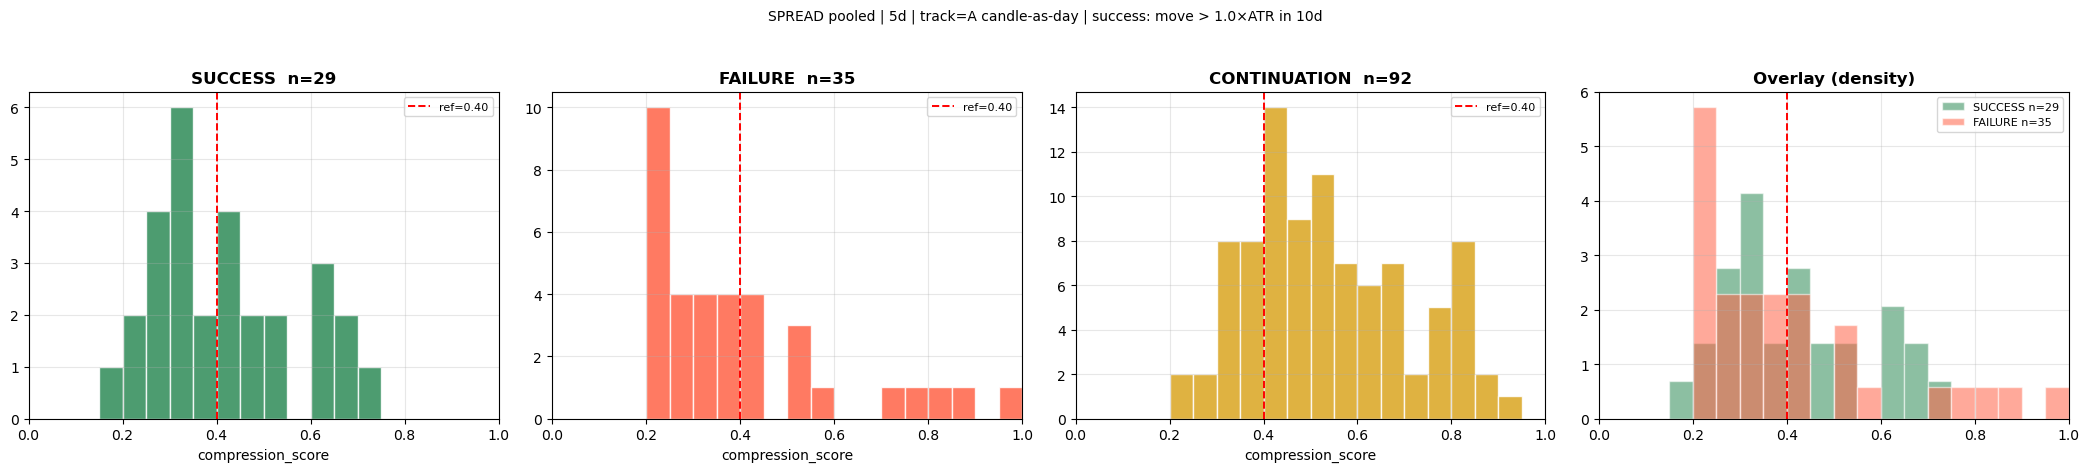


  JUMBO pooled | 5d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=82  CENSORED=33  SUCCESS=27  FAILURE=22   | base rate (S/(S+F)) = 0.551

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,1,0,1,0.00
"[0.2, 0.25)",2,2,0,4,0.50
"[0.25, 0.3)",2,3,6,11,0.40
"[0.3, 0.35)",10,2,6,18,0.83
"[0.35, 0.4)",2,1,5,8,0.67
"[0.4, 0.45)",5,1,6,12,0.83



  Threshold sweep  | base=0.551  PR-AUC=0.452


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,49,0.551,"[0.469, 0.633]",1.000,0.711,—,1.000,27,22,0,0,False
1,0.050,49,0.551,"[0.469, 0.633]",1.000,0.711,—,1.000,27,22,0,0,False
2,0.100,49,0.551,"[0.469, 0.633]",1.000,0.711,—,1.000,27,22,0,0,False
3,0.150,49,0.551,"[0.469, 0.633]",1.000,0.711,—,1.000,27,22,0,0,False
4,0.200,48,0.562,"[0.469, 0.646]",1.000,0.720,0.160,1.021,27,21,0,1,False
5,0.250,44,0.568,"[0.458, 0.667]",0.926,0.704,0.102,1.031,25,19,2,3,False
6,0.300,39,0.590,"[0.465, 0.722]",0.852,0.697,0.154,1.070,23,16,4,6,False
7,0.350,27,0.481,"[0.333, 0.698]",0.481,0.481,-0.155,0.874,13,14,14,8,False
8,0.400,24,0.458,"[0.327, 0.683]",0.407,0.431,-0.183,0.832,11,13,16,9,False
9,0.450,18,0.333,"[0.100, 0.588]",0.222,0.267,-0.333,0.605,6,12,21,10,False


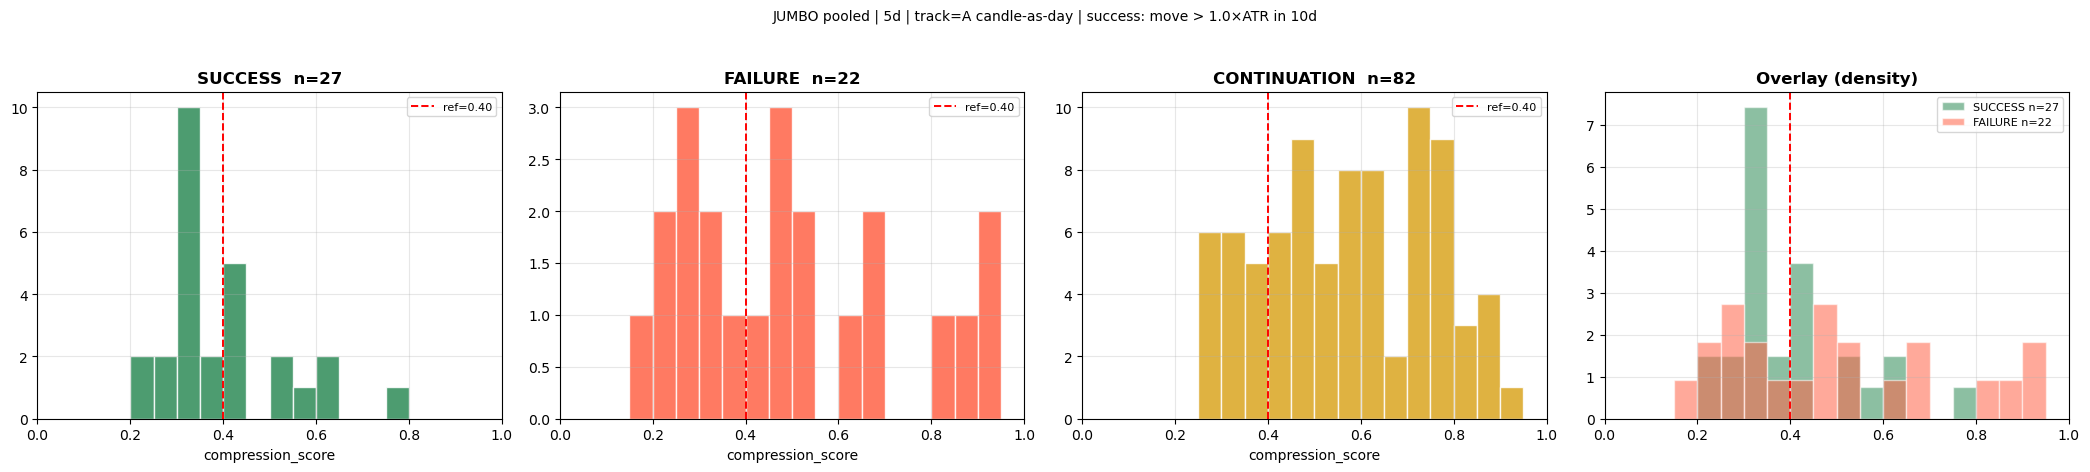


  SPREAD pooled | 2d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  SUCCESS=37  CENSORED=35  CONTINUATION=22  FAILURE=17   | base rate (S/(S+F)) = 0.685

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,1,0,2,0.50
"[0.25, 0.3)",3,1,0,4,0.75
"[0.3, 0.35)",5,1,1,7,0.83
"[0.35, 0.4)",6,0,3,9,1.00
"[0.4, 0.45)",7,4,4,15,0.64



  Threshold sweep  | base=0.685  PR-AUC=0.620


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,54,0.685,"[0.593, 0.778]",1.000,0.813,—,1.000,37,17,0,0,False
1,0.050,54,0.685,"[0.593, 0.778]",1.000,0.813,—,1.000,37,17,0,0,False
2,0.100,54,0.685,"[0.593, 0.778]",1.000,0.813,—,1.000,37,17,0,0,False
3,0.150,54,0.685,"[0.593, 0.778]",1.000,0.813,—,1.000,37,17,0,0,False
4,0.200,54,0.685,"[0.593, 0.778]",1.000,0.813,—,1.000,37,17,0,0,False
5,0.250,52,0.692,"[0.600, 0.788]",0.973,0.809,0.078,1.010,36,16,1,1,False
6,0.300,48,0.688,"[0.585, 0.812]",0.892,0.776,0.014,1.003,33,15,4,2,False
7,0.350,42,0.667,"[0.562, 0.836]",0.757,0.709,-0.075,0.973,28,14,9,3,False
8,0.400,36,0.611,"[0.471, 0.824]",0.595,0.603,-0.226,0.892,22,14,15,3,False
9,0.450,25,0.600,"[0.455, 0.811]",0.405,0.484,-0.170,0.876,15,10,22,7,False


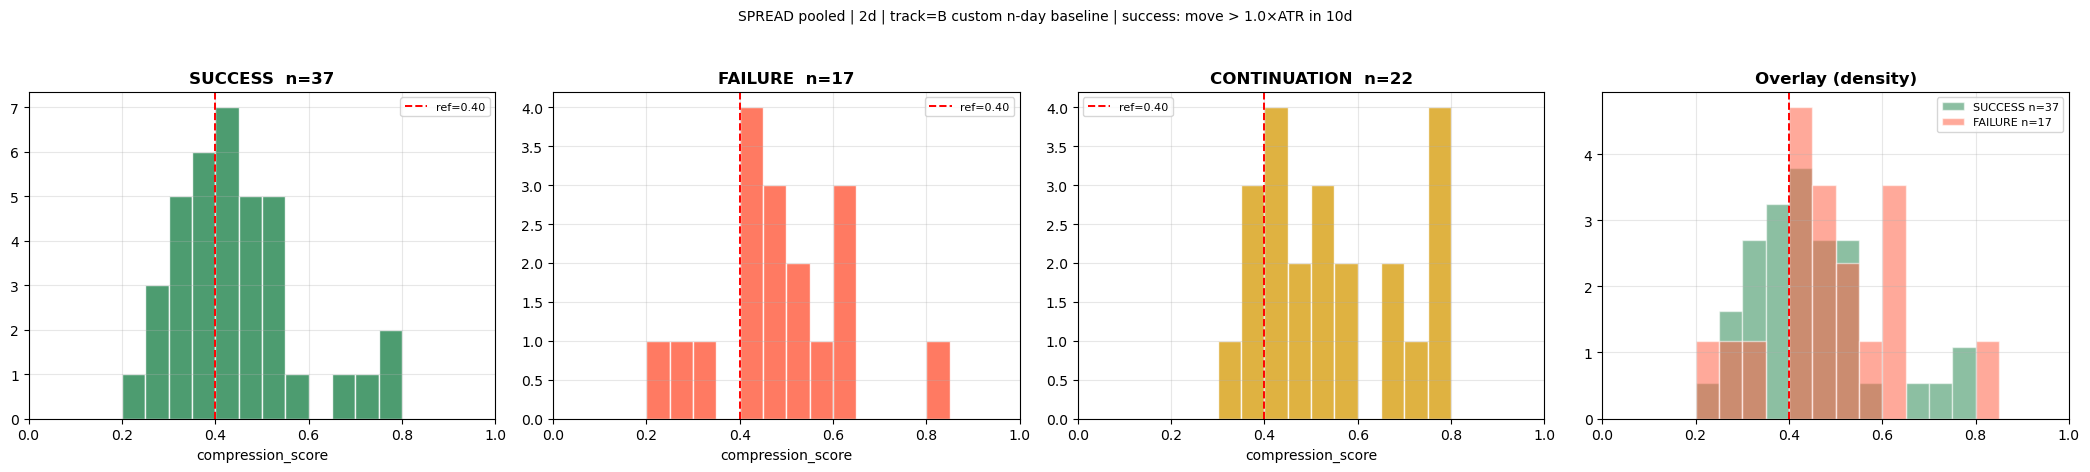


  JUMBO pooled | 2d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CENSORED=32  SUCCESS=31  CONTINUATION=25  FAILURE=7   | base rate (S/(S+F)) = 0.816

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,0,0,--
"[0.25, 0.3)",4,0,4,8,1.00
"[0.3, 0.35)",3,2,2,7,0.60
"[0.35, 0.4)",3,1,0,4,0.75
"[0.4, 0.45)",7,0,4,11,1.00



  Threshold sweep  | base=0.816  PR-AUC=0.801


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
1,0.050,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
2,0.100,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
3,0.150,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
4,0.200,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
5,0.250,38,0.816,"[0.711, 0.974]",1.000,0.899,—,1.000,31,7,0,0,False
6,0.300,34,0.794,"[0.690, 0.970]",0.871,0.831,-0.163,0.973,27,7,4,0,False
7,0.350,29,0.828,"[0.676, 0.968]",0.774,0.800,0.055,1.014,24,5,7,2,False
8,0.400,25,0.840,"[0.724, 0.963]",0.677,0.750,0.087,1.030,21,4,10,3,False
9,0.450,18,0.778,"[0.692, 0.939]",0.452,0.571,-0.093,0.953,14,4,17,3,False


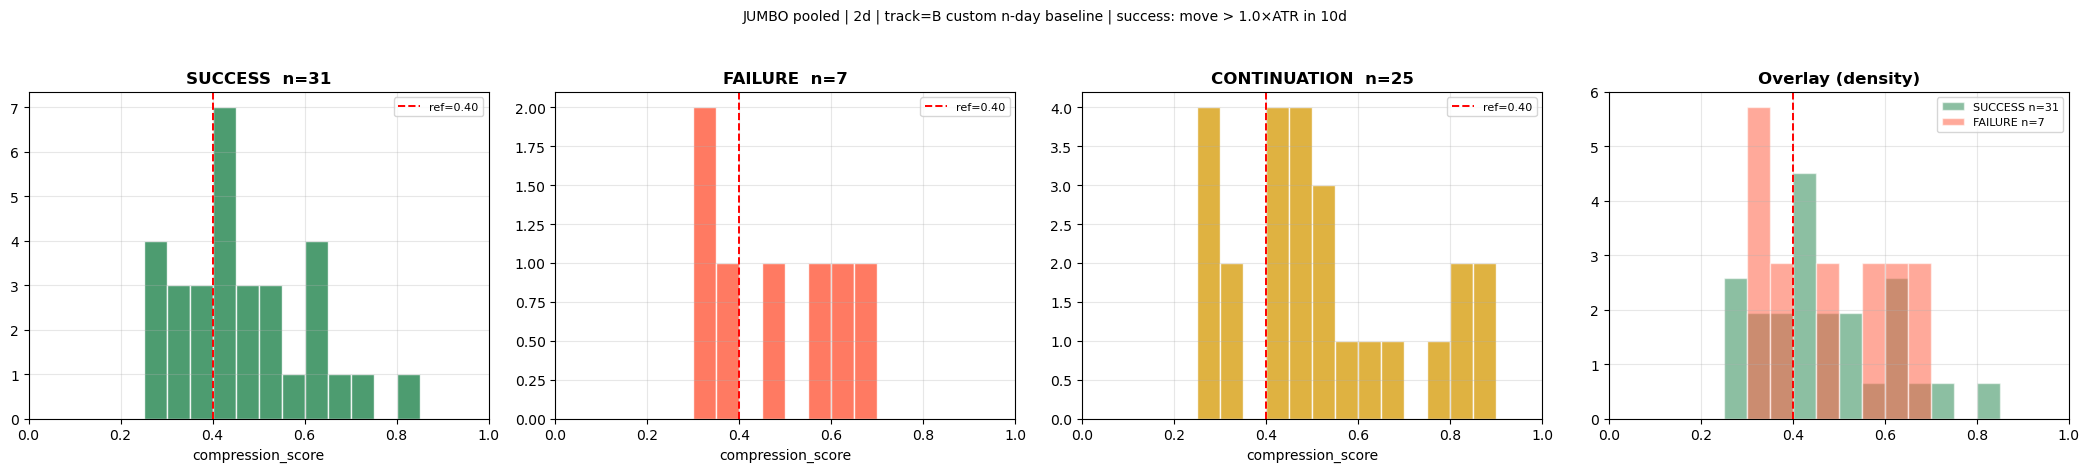


  SPREAD pooled | 3d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CENSORED=32  SUCCESS=19  CONTINUATION=16  FAILURE=9   | base rate (S/(S+F)) = 0.679

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,0,0,1,1.00
"[0.25, 0.3)",4,2,0,6,0.67
"[0.3, 0.35)",3,0,0,3,1.00
"[0.35, 0.4)",1,1,1,3,0.50
"[0.4, 0.45)",1,1,1,3,0.50



  Threshold sweep  | base=0.679  PR-AUC=0.577


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,28,0.679,"[0.643, 0.750]",1.000,0.809,—,1.000,19,9,0,0,False
1,0.050,28,0.679,"[0.643, 0.750]",1.000,0.809,—,1.000,19,9,0,0,False
2,0.100,28,0.679,"[0.643, 0.750]",1.000,0.809,—,1.000,19,9,0,0,False
3,0.150,28,0.679,"[0.643, 0.750]",1.000,0.809,—,1.000,19,9,0,0,False
4,0.200,28,0.679,"[0.643, 0.750]",1.000,0.809,—,1.000,19,9,0,0,False
5,0.250,27,0.667,"[0.630, 0.750]",0.947,0.783,-0.132,0.982,18,9,1,0,False
6,0.300,21,0.667,"[0.632, 0.822]",0.737,0.700,-0.044,0.982,14,7,5,2,False
7,0.350,18,0.611,"[0.562, 0.789]",0.579,0.595,-0.194,0.901,11,7,8,2,False
8,0.400,16,0.625,"[0.571, 0.789]",0.526,0.571,-0.132,0.921,10,6,9,3,False
9,0.450,14,0.643,"[0.571, 0.769]",0.474,0.545,-0.076,0.947,9,5,10,4,False


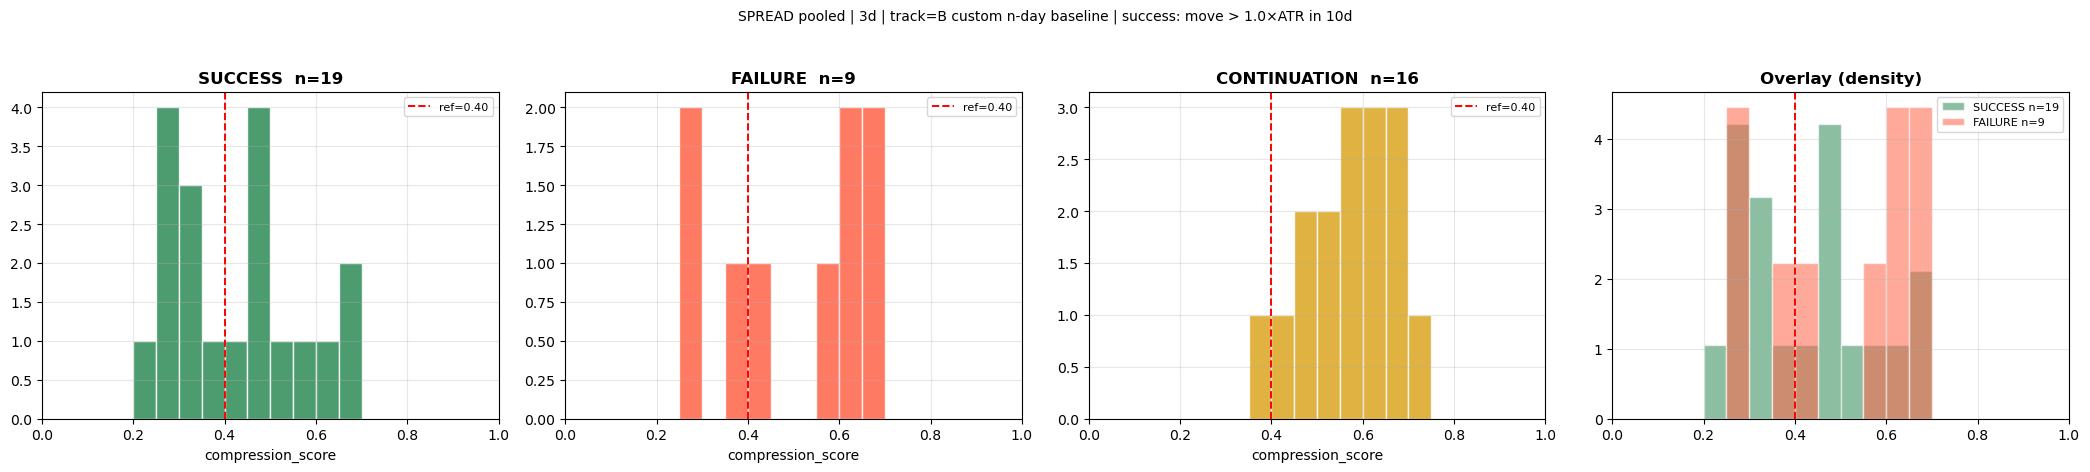


  JUMBO pooled | 3d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CENSORED=31  CONTINUATION=14  FAILURE=10  SUCCESS=10   | base rate (S/(S+F)) = 0.500

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,1,1,2,0.00
"[0.25, 0.3)",1,1,0,2,0.50
"[0.3, 0.35)",1,1,1,3,0.50
"[0.35, 0.4)",4,0,1,5,1.00
"[0.4, 0.45)",3,1,2,6,0.75



  Threshold sweep  | base=0.500  PR-AUC=0.378


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,20,0.500,"[0.300, 0.650]",1.000,0.667,—,1.000,10,10,0,0,False
1,0.050,20,0.500,"[0.300, 0.650]",1.000,0.667,—,1.000,10,10,0,0,False
2,0.100,20,0.500,"[0.300, 0.650]",1.000,0.667,—,1.000,10,10,0,0,False
3,0.150,20,0.500,"[0.300, 0.650]",1.000,0.667,—,1.000,10,10,0,0,False
4,0.200,20,0.500,"[0.300, 0.650]",1.000,0.667,—,1.000,10,10,0,0,False
5,0.250,19,0.526,"[0.333, 0.722]",1.000,0.690,0.229,1.053,10,9,0,1,False
6,0.300,17,0.529,"[0.375, 0.688]",0.900,0.667,0.140,1.059,9,8,1,2,False
7,0.350,15,0.533,"[0.308, 0.643]",0.800,0.640,0.115,1.067,8,7,2,3,False
8,0.400,11,0.364,"[0.174, 0.500]",0.400,0.381,-0.302,0.727,4,7,6,3,False
9,0.450,7,0.143,"[0.000, 0.333]",0.100,0.118,-0.524,0.286,1,6,9,4,True


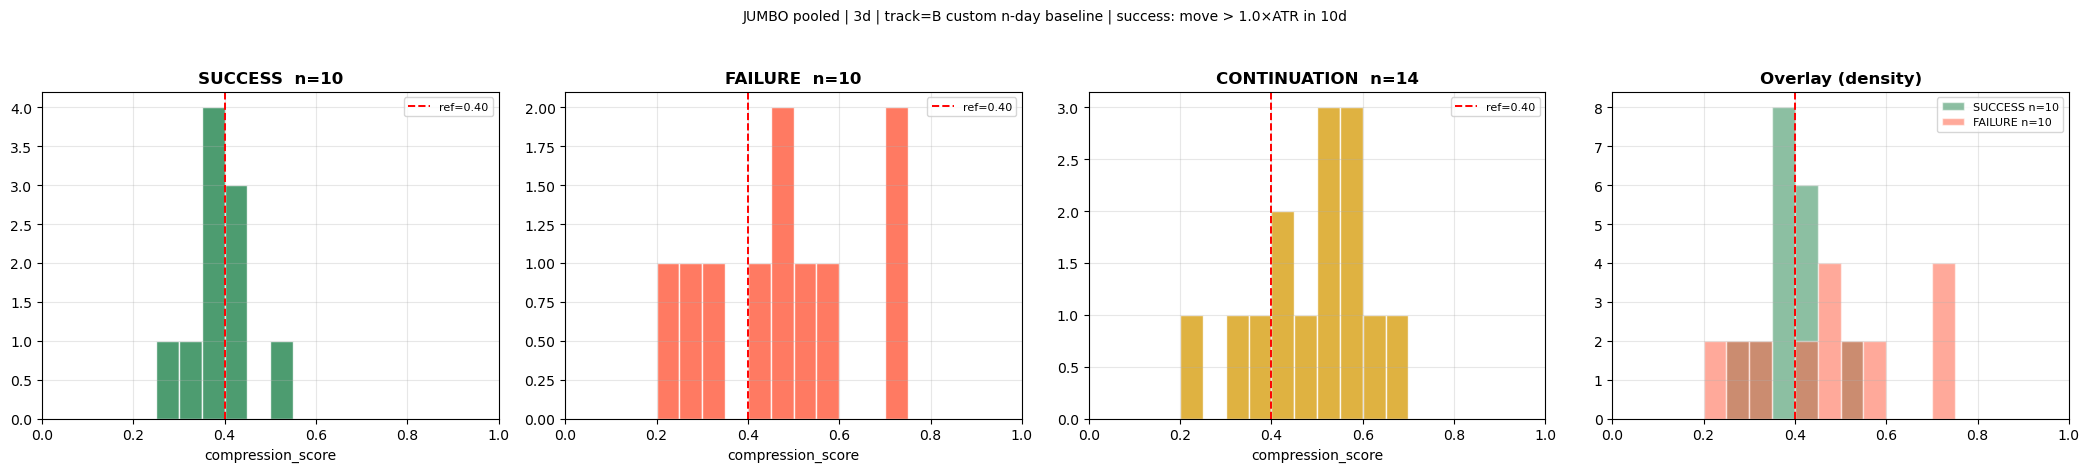


  SPREAD pooled | 5d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CENSORED=20  FAILURE=3  CONTINUATION=2  SUCCESS=2   | base rate (S/(S+F)) = 0.400

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,0,0,--
"[0.25, 0.3)",0,0,0,0,--
"[0.3, 0.35)",1,3,1,5,0.25
"[0.35, 0.4)",1,0,0,1,1.00
"[0.4, 0.45)",0,0,1,1,--



  Threshold sweep  | base=0.400  PR-AUC=0.708


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
1,0.050,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
2,0.100,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
3,0.150,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
4,0.200,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
5,0.250,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
6,0.300,5,0.400,"[0.400, 0.400]",1.000,0.571,—,1.000,2,3,0,0,True
7,0.350,1,1.000,"[1.000, 1.000]",0.500,0.667,0.612,2.500,1,0,1,3,True
8,0.400,0,—,n/a,0.000,—,—,—,0,0,2,3,True
9,0.450,0,—,n/a,0.000,—,—,—,0,0,2,3,True


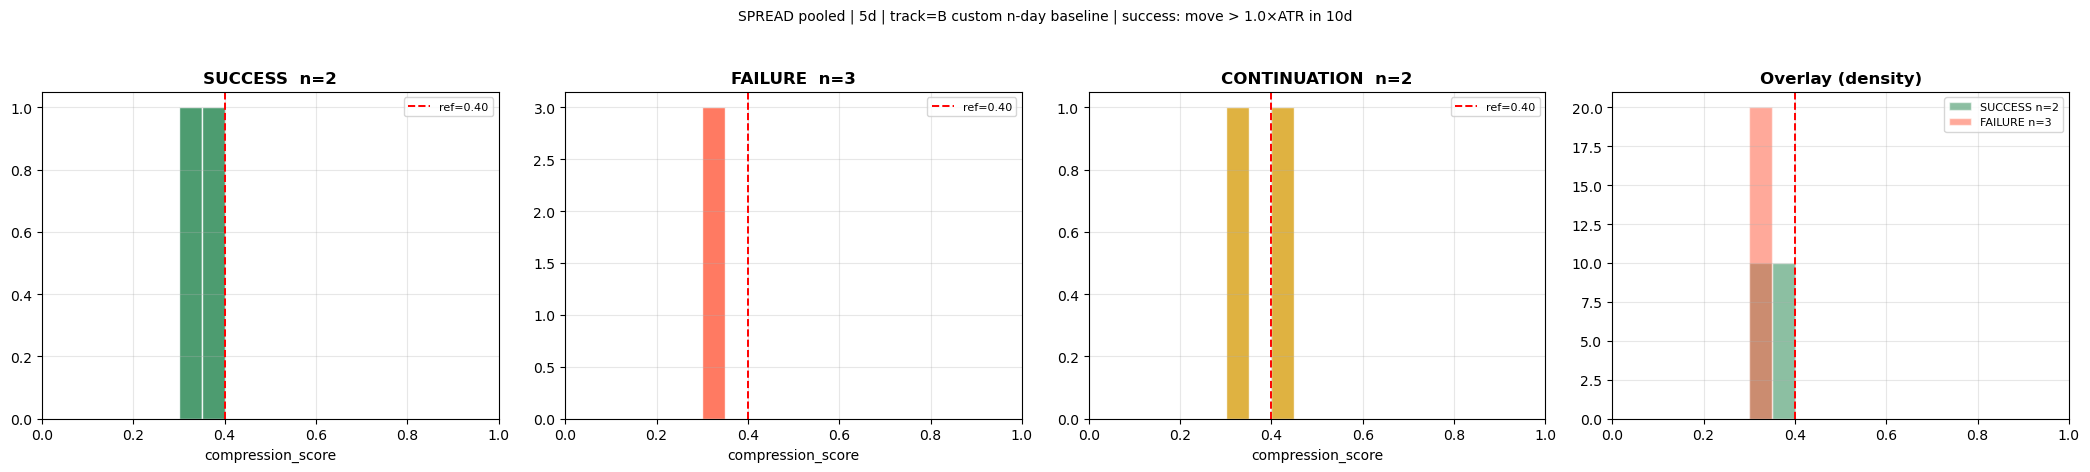


  JUMBO pooled | 5d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CENSORED=17  SUCCESS=2  FAILURE=2  CONTINUATION=1   | base rate (S/(S+F)) = 0.500

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,0,0,--
"[0.25, 0.3)",0,0,0,0,--
"[0.3, 0.35)",1,0,0,1,1.00
"[0.35, 0.4)",1,0,0,1,1.00
"[0.4, 0.45)",0,0,0,0,--



  Threshold sweep  | base=0.500  PR-AUC=0.292


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
1,0.050,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
2,0.100,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
3,0.150,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
4,0.200,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
5,0.250,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
6,0.300,4,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,2,2,0,0,True
7,0.350,3,0.333,"[0.333, 0.333]",0.500,0.400,-0.577,0.667,1,2,1,0,True
8,0.400,2,0.000,"[0.000, 0.000]",0.000,—,-1.000,0.000,0,2,2,0,True
9,0.450,2,0.000,"[0.000, 0.000]",0.000,—,-1.000,0.000,0,2,2,0,True


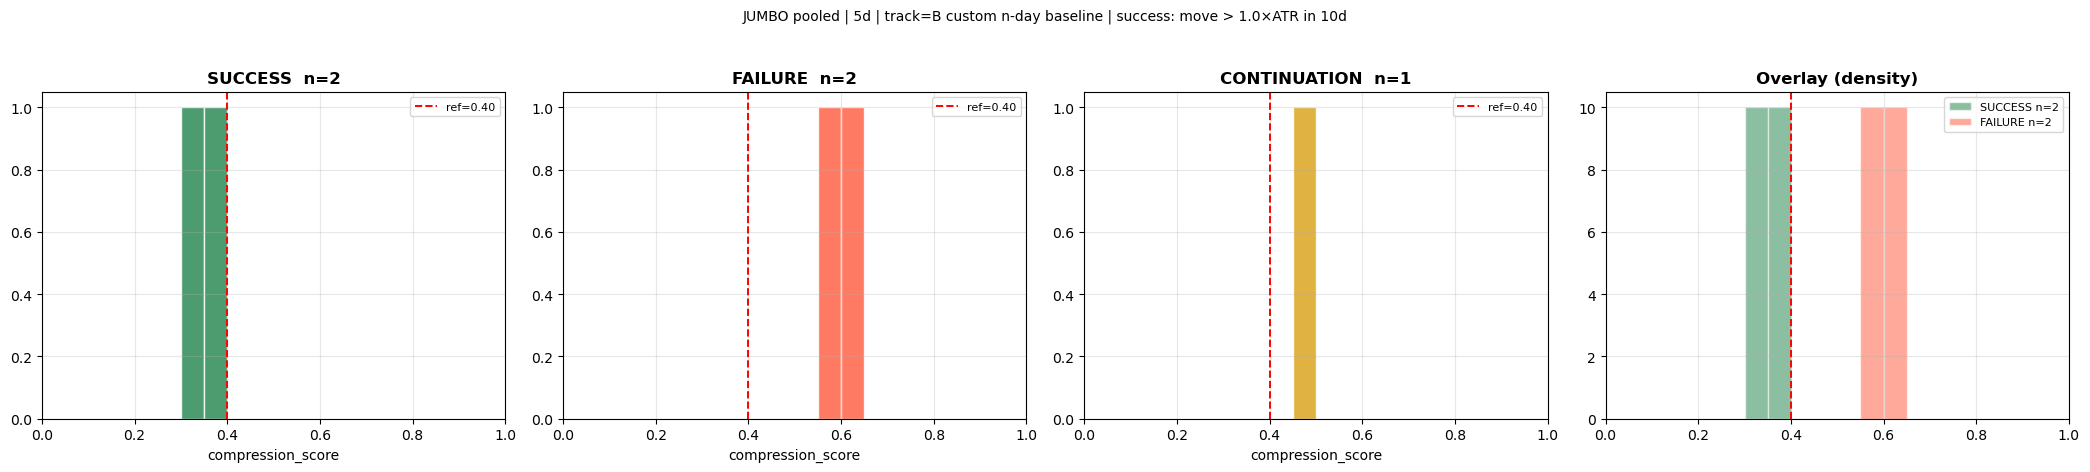


##############################################################################
  PER-INSTRUMENT SUMMARY
##############################################################################


,track,horizon,structure,instrument,signals,success,failure,continuation,censored,base_rate
0,candle,1d,spread,BOZ26-F27,33,13,2,9,9,0.866667
1,candle,1d,spread,BOF27-H27,22,9,1,5,7,0.900000
2,candle,1d,spread,BOH27-K27,29,16,1,7,5,0.941176
3,candle,1d,spread,BOK27-N27,31,16,3,5,7,0.842105
4,candle,1d,spread,BON27-Q27,32,19,2,8,3,0.904762
...,...,...,...,...,...,...,...,...,...,...
65,custom,5d,jumbo,BOZ26-H27,2,1,0,0,1,1.000000
66,custom,5d,jumbo,BOZ26-K27,4,0,0,0,4,NaN
67,custom,5d,jumbo,BOF27-K27,4,0,0,0,4,NaN
68,custom,5d,jumbo,BOF27-N27,5,0,1,0,4,0.000000


In [5]:
res = run_compression_atr_analysis(
    product_code = "BO",
    horizons     = ["1d", "2d", "3d", "5d"],
    tracks       = ("candle", "custom"),
    months_back  = 6,
    front_n      = 5,
    k_atr        = 1.0,
)
# res["summary"], res["labeled"][("custom","3d","spread")], res["sweeps"][...]

  [FETCH] SMN27-Q27  2026-04-01 → 2026-10-01
  [FETCH] SMF27-N27  2026-04-01 → 2026-10-01
  [FETCH] SMH27-N27  2026-04-01 → 2026-10-01
Fetched 10 instruments | k_atr=1.0  fwd=10d  ATR period=10  continuation=exclude

  SPREAD pooled | 1d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  SUCCESS=69  CONTINUATION=34  FAILURE=3  CENSORED=2   | base rate (S/(S+F)) = 0.958

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,3,3,--
"[0.25, 0.3)",5,0,3,8,1.00
"[0.3, 0.35)",10,0,3,13,1.00
"[0.35, 0.4)",6,1,4,11,0.86
"[0.4, 0.45)",9,1,1,11,0.90



  Threshold sweep  | base=0.958  PR-AUC=0.944


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
1,0.050,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
2,0.100,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
3,0.150,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
4,0.200,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
5,0.250,72,0.958,"[0.917, 0.986]",1.000,0.979,—,1.000,69,3,0,0,False
6,0.300,67,0.955,"[0.907, 0.986]",0.928,0.941,-0.057,0.997,64,3,5,0,False
7,0.350,57,0.947,"[0.894, 0.983]",0.783,0.857,-0.107,0.989,54,3,15,0,False
8,0.400,50,0.960,"[0.907, 1.000]",0.696,0.807,0.013,1.002,48,2,21,1,False
9,0.450,40,0.975,"[0.916, 1.000]",0.565,0.716,0.093,1.017,39,1,30,2,False


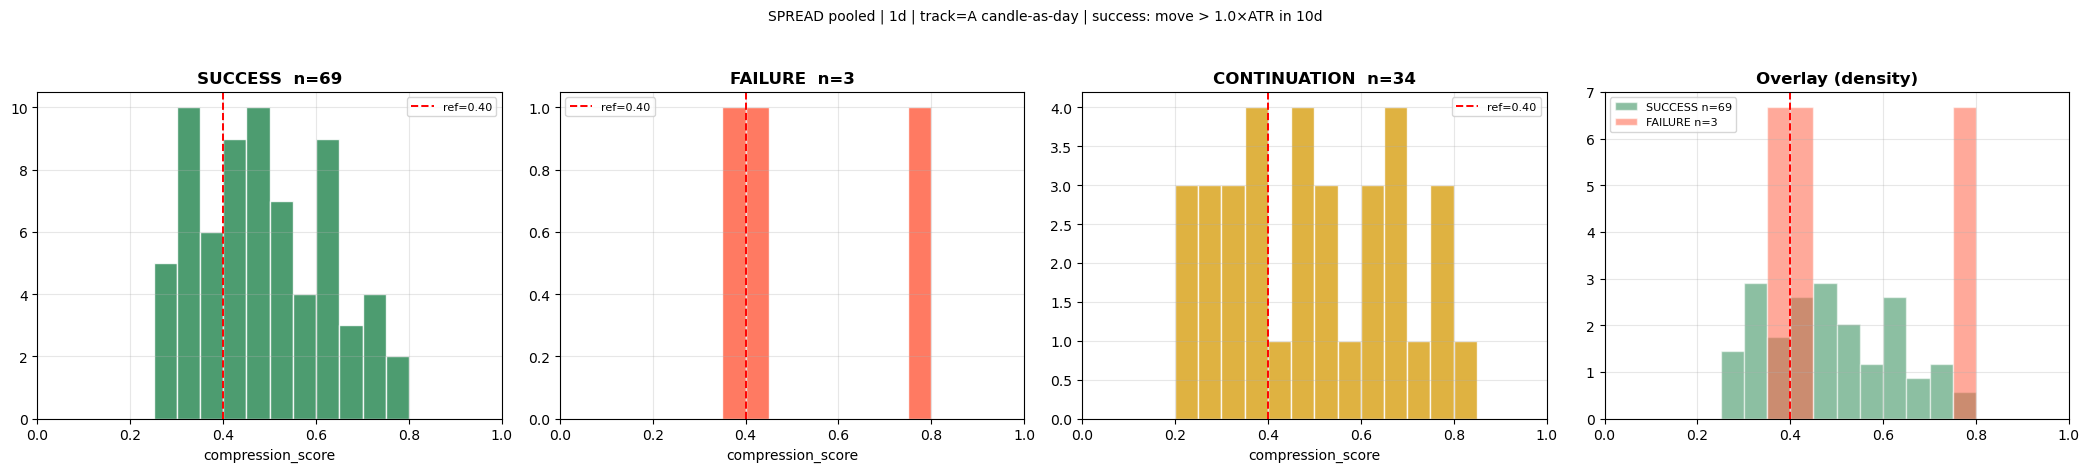


  JUMBO pooled | 1d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  SUCCESS=51  CONTINUATION=24  CENSORED=3   | base rate (S/(S+F)) = 1.000

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",3,0,1,4,1.00
"[0.25, 0.3)",2,0,1,3,1.00
"[0.3, 0.35)",3,0,2,5,1.00
"[0.35, 0.4)",5,0,4,9,1.00
"[0.4, 0.45)",8,0,2,10,1.00



  Threshold sweep  | base=1.000  PR-AUC=nan


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,51,1.000,"[1.000, 1.000]",1.000,1.000,—,1.000,51,0,0,0,False
1,0.050,51,1.000,"[1.000, 1.000]",1.000,1.000,—,1.000,51,0,0,0,False
2,0.100,51,1.000,"[1.000, 1.000]",1.000,1.000,—,1.000,51,0,0,0,False
3,0.150,51,1.000,"[1.000, 1.000]",1.000,1.000,—,1.000,51,0,0,0,False
4,0.200,51,1.000,"[1.000, 1.000]",1.000,1.000,—,1.000,51,0,0,0,False
5,0.250,48,1.000,"[1.000, 1.000]",0.941,0.970,0.000,1.000,48,0,3,0,False
6,0.300,46,1.000,"[1.000, 1.000]",0.902,0.948,0.000,1.000,46,0,5,0,False
7,0.350,43,1.000,"[1.000, 1.000]",0.843,0.915,0.000,1.000,43,0,8,0,False
8,0.400,38,1.000,"[1.000, 1.000]",0.745,0.854,0.000,1.000,38,0,13,0,False
9,0.450,30,1.000,"[1.000, 1.000]",0.588,0.741,0.000,1.000,30,0,21,0,False


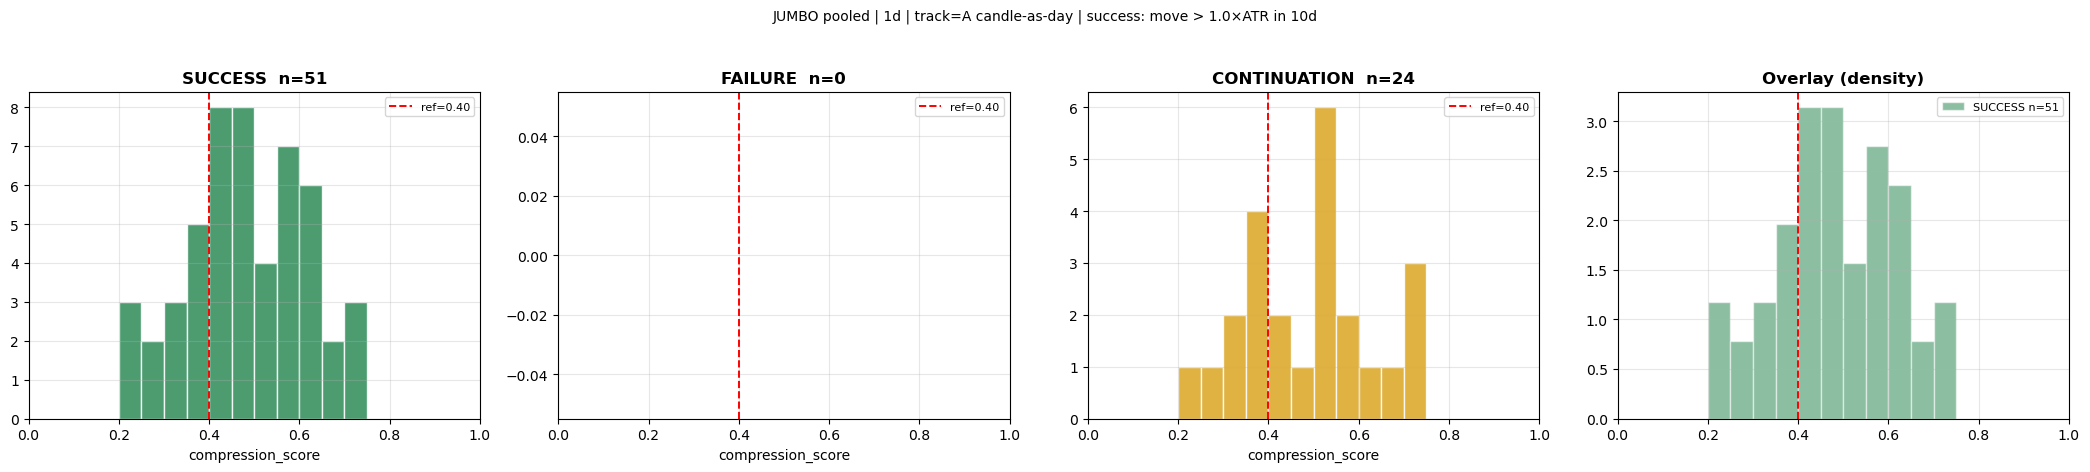


  SPREAD pooled | 2d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=56  SUCCESS=53  FAILURE=12  CENSORED=5   | base rate (S/(S+F)) = 0.815

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",3,2,1,6,0.60
"[0.25, 0.3)",2,1,7,10,0.67
"[0.3, 0.35)",5,1,5,11,0.83
"[0.35, 0.4)",9,1,7,17,0.90
"[0.4, 0.45)",8,3,3,14,0.73



  Threshold sweep  | base=0.815  PR-AUC=0.864


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,65,0.815,"[0.692, 0.877]",1.000,0.898,—,1.000,53,12,0,0,False
1,0.050,65,0.815,"[0.692, 0.877]",1.000,0.898,—,1.000,53,12,0,0,False
2,0.100,65,0.815,"[0.692, 0.877]",1.000,0.898,—,1.000,53,12,0,0,False
3,0.150,65,0.815,"[0.692, 0.877]",1.000,0.898,—,1.000,53,12,0,0,False
4,0.200,65,0.815,"[0.692, 0.877]",1.000,0.898,—,1.000,53,12,0,0,False
5,0.250,60,0.833,"[0.714, 0.887]",0.943,0.885,0.160,1.022,50,10,3,2,False
6,0.300,57,0.842,"[0.731, 0.883]",0.906,0.873,0.184,1.033,48,9,5,3,False
7,0.350,51,0.843,"[0.726, 0.900]",0.811,0.827,0.137,1.034,43,8,10,4,False
8,0.400,41,0.829,"[0.697, 0.890]",0.642,0.723,0.047,1.017,34,7,19,5,False
9,0.450,30,0.867,"[0.779, 0.920]",0.491,0.627,0.122,1.063,26,4,27,8,False


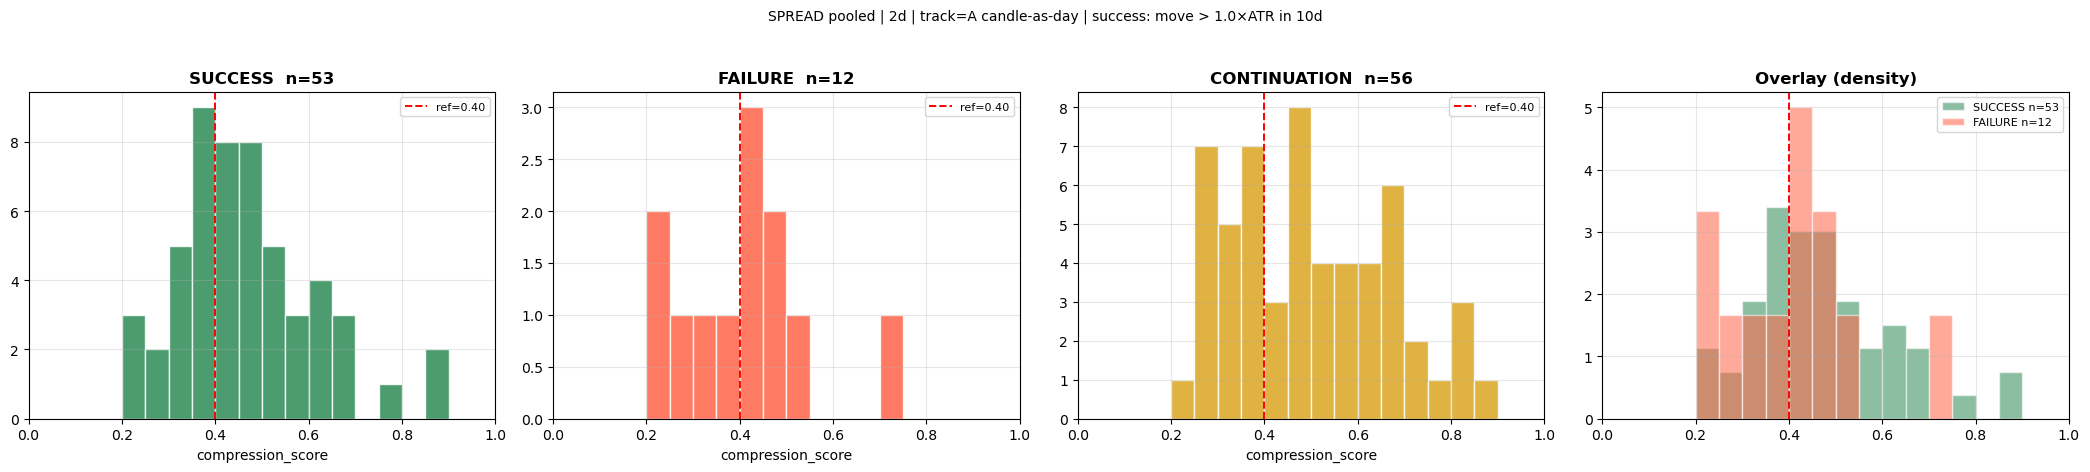


  JUMBO pooled | 2d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  SUCCESS=43  CONTINUATION=38  FAILURE=7  CENSORED=3   | base rate (S/(S+F)) = 0.860

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,0,0,1,1.00
"[0.25, 0.3)",3,1,0,4,0.75
"[0.3, 0.35)",3,1,2,6,0.75
"[0.35, 0.4)",7,1,2,10,0.88
"[0.4, 0.45)",8,1,4,13,0.89



  Threshold sweep  | base=0.860  PR-AUC=0.872


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,50,0.860,"[0.840, 0.940]",1.000,0.925,—,1.000,43,7,0,0,False
1,0.050,50,0.860,"[0.840, 0.940]",1.000,0.925,—,1.000,43,7,0,0,False
2,0.100,50,0.860,"[0.840, 0.940]",1.000,0.925,—,1.000,43,7,0,0,False
3,0.150,50,0.860,"[0.840, 0.940]",1.000,0.925,—,1.000,43,7,0,0,False
4,0.200,50,0.860,"[0.840, 0.940]",1.000,0.925,—,1.000,43,7,0,0,False
5,0.250,49,0.857,"[0.837, 0.940]",0.977,0.913,-0.058,0.997,42,7,1,0,False
6,0.300,45,0.867,"[0.850, 0.978]",0.907,0.886,0.058,1.008,39,6,4,1,False
7,0.350,41,0.878,"[0.861, 1.000]",0.837,0.857,0.111,1.021,36,5,7,2,False
8,0.400,33,0.879,"[0.853, 1.000]",0.674,0.763,0.075,1.022,29,4,14,3,False
9,0.450,24,0.875,"[0.846, 1.000]",0.488,0.627,0.042,1.017,21,3,22,4,False


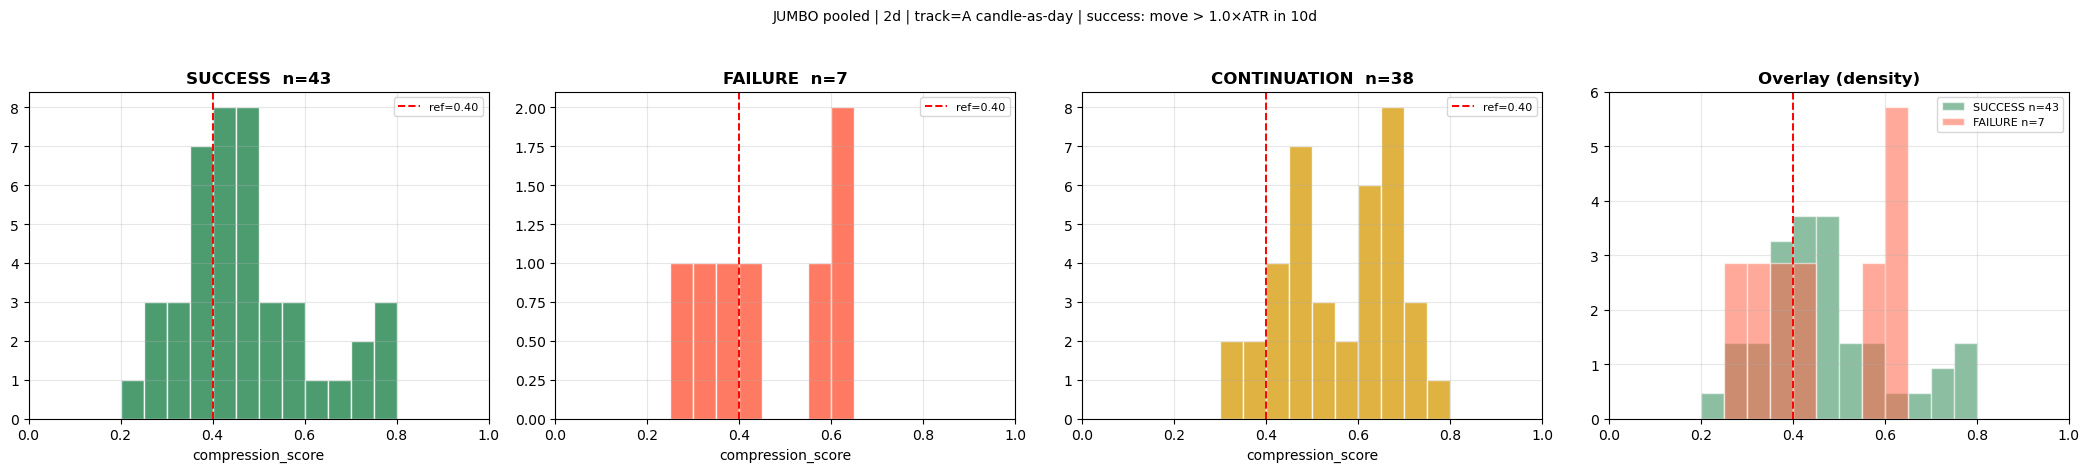


  SPREAD pooled | 3d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=67  SUCCESS=42  FAILURE=23  CENSORED=3   | base rate (S/(S+F)) = 0.646

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,3,0,3,0.00
"[0.2, 0.25)",1,0,0,1,1.00
"[0.25, 0.3)",3,3,7,13,0.50
"[0.3, 0.35)",10,3,7,20,0.77
"[0.35, 0.4)",5,3,6,14,0.62
"[0.4, 0.45)",4,1,8,13,0.80



  Threshold sweep  | base=0.646  PR-AUC=0.756


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,65,0.646,"[0.538, 0.708]",1.000,0.785,—,1.000,42,23,0,0,False
1,0.050,65,0.646,"[0.538, 0.708]",1.000,0.785,—,1.000,42,23,0,0,False
2,0.100,65,0.646,"[0.538, 0.708]",1.000,0.785,—,1.000,42,23,0,0,False
3,0.150,65,0.646,"[0.538, 0.708]",1.000,0.785,—,1.000,42,23,0,0,False
4,0.200,62,0.677,"[0.560, 0.763]",1.000,0.808,0.297,1.048,42,20,0,3,False
5,0.250,61,0.672,"[0.560, 0.763]",0.976,0.796,0.212,1.040,41,20,1,3,False
6,0.300,55,0.691,"[0.595, 0.757]",0.905,0.784,0.220,1.069,38,17,4,6,False
7,0.350,42,0.667,"[0.527, 0.756]",0.667,0.667,0.058,1.032,28,14,14,9,False
8,0.400,34,0.676,"[0.552, 0.778]",0.548,0.605,0.066,1.047,23,11,19,12,False
9,0.450,29,0.655,"[0.500, 0.786]",0.452,0.535,0.017,1.014,19,10,23,13,False


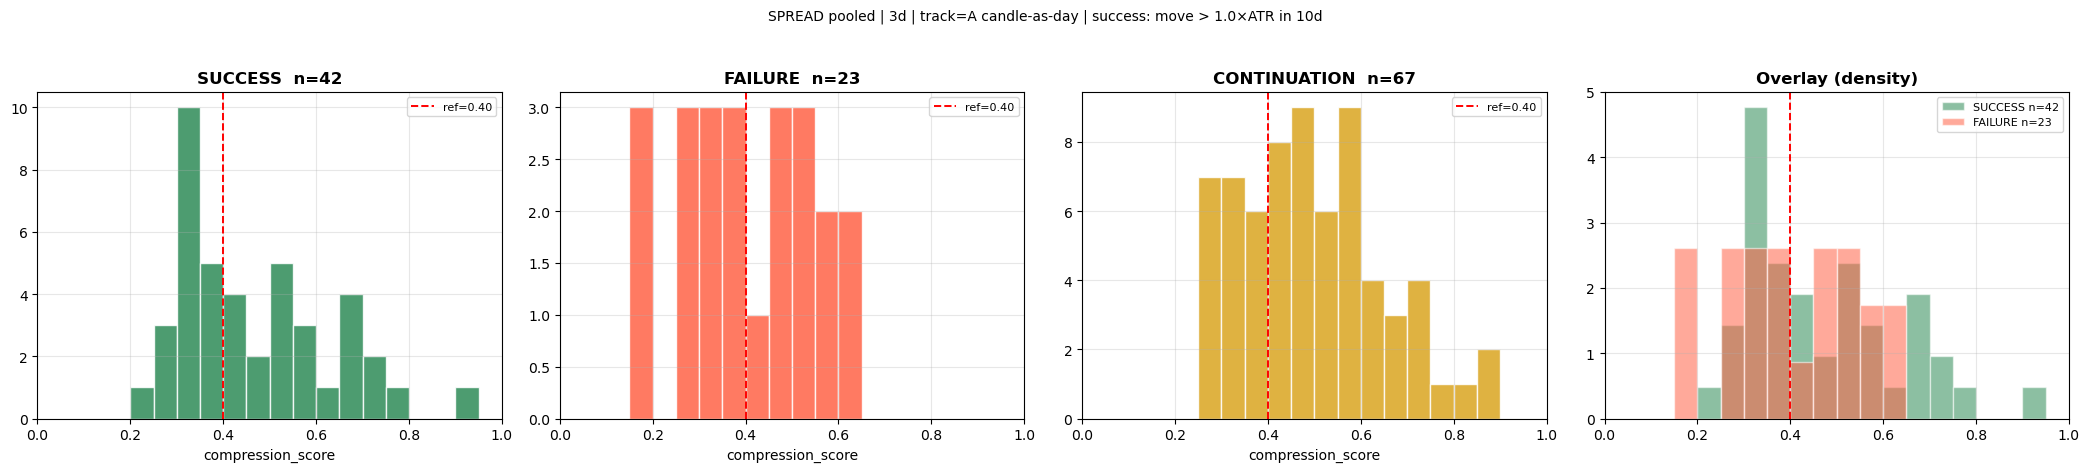


  JUMBO pooled | 3d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=43  SUCCESS=33  FAILURE=10  CENSORED=2   | base rate (S/(S+F)) = 0.767

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,1,0,2,0.50
"[0.25, 0.3)",2,2,1,5,0.50
"[0.3, 0.35)",3,0,3,6,1.00
"[0.35, 0.4)",1,0,3,4,1.00
"[0.4, 0.45)",5,1,5,11,0.83



  Threshold sweep  | base=0.767  PR-AUC=0.761


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,43,0.767,"[0.721, 0.884]",1.000,0.868,—,1.000,33,10,0,0,False
1,0.050,43,0.767,"[0.721, 0.884]",1.000,0.868,—,1.000,33,10,0,0,False
2,0.100,43,0.767,"[0.721, 0.884]",1.000,0.868,—,1.000,33,10,0,0,False
3,0.150,43,0.767,"[0.721, 0.884]",1.000,0.868,—,1.000,33,10,0,0,False
4,0.200,43,0.767,"[0.721, 0.884]",1.000,0.868,—,1.000,33,10,0,0,False
5,0.250,41,0.780,"[0.721, 0.950]",0.970,0.865,0.140,1.017,32,9,1,1,False
6,0.300,37,0.811,"[0.806, 0.974]",0.909,0.857,0.255,1.057,30,7,3,3,False
7,0.350,34,0.794,"[0.778, 0.971]",0.818,0.806,0.123,1.035,27,7,6,3,False
8,0.400,33,0.788,"[0.774, 0.971]",0.788,0.788,0.088,1.027,26,7,7,3,False
9,0.450,27,0.778,"[0.789, 1.000]",0.636,0.700,0.032,1.013,21,6,12,4,False


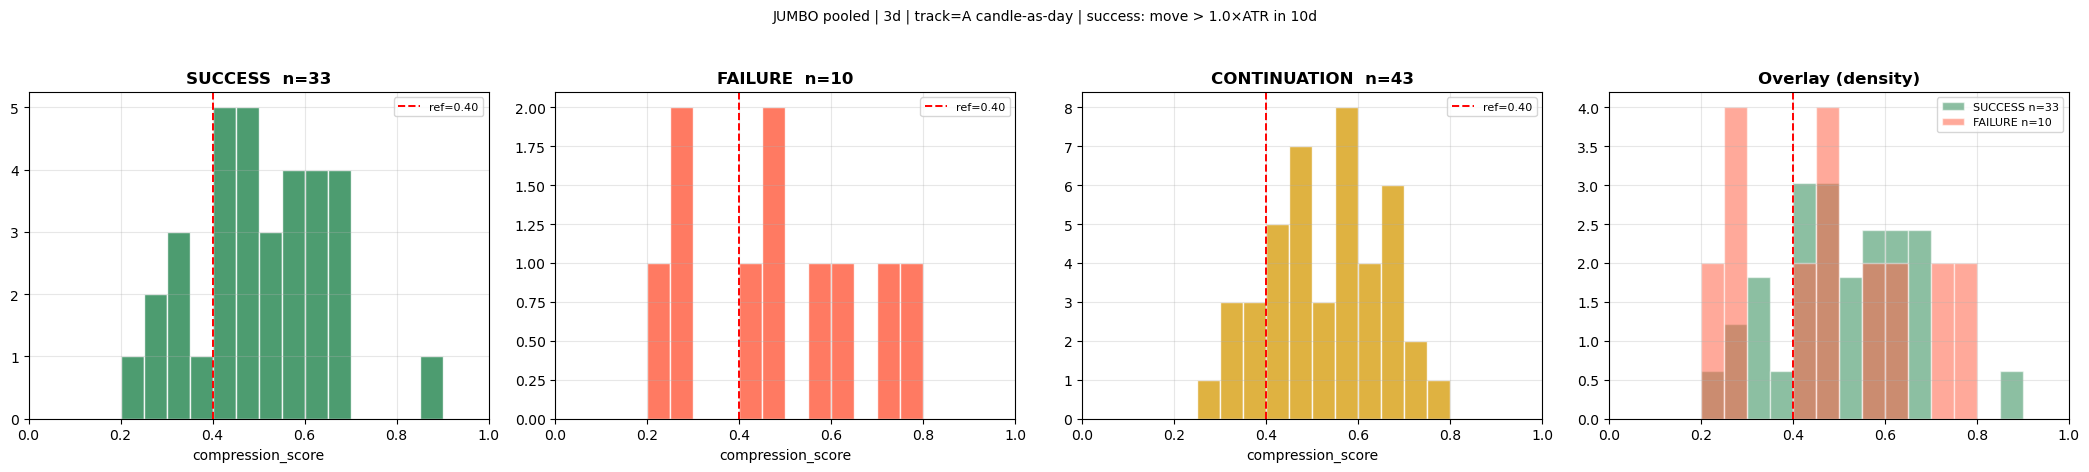


  SPREAD pooled | 5d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=90  FAILURE=28  SUCCESS=22  CENSORED=6   | base rate (S/(S+F)) = 0.440

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,3,2,6,0.25
"[0.25, 0.3)",1,3,5,9,0.25
"[0.3, 0.35)",3,4,9,16,0.43
"[0.35, 0.4)",6,4,15,25,0.60
"[0.4, 0.45)",3,3,11,17,0.50



  Threshold sweep  | base=0.440  PR-AUC=0.437


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,50,0.440,"[0.360, 0.540]",1.000,0.611,—,1.000,22,28,0,0,False
1,0.050,50,0.440,"[0.360, 0.540]",1.000,0.611,—,1.000,22,28,0,0,False
2,0.100,50,0.440,"[0.360, 0.540]",1.000,0.611,—,1.000,22,28,0,0,False
3,0.150,50,0.440,"[0.360, 0.540]",1.000,0.611,—,1.000,22,28,0,0,False
4,0.200,50,0.440,"[0.360, 0.540]",1.000,0.611,—,1.000,22,28,0,0,False
5,0.250,46,0.457,"[0.375, 0.578]",0.955,0.618,0.113,1.038,21,25,1,3,False
6,0.300,42,0.476,"[0.375, 0.615]",0.909,0.625,0.167,1.082,20,22,2,6,False
7,0.350,35,0.486,"[0.375, 0.667]",0.773,0.596,0.141,1.104,17,18,5,10,False
8,0.400,25,0.440,"[0.261, 0.694]",0.500,0.468,0.000,1.000,11,14,11,14,False
9,0.450,19,0.421,"[0.267, 0.667]",0.364,0.390,-0.030,0.957,8,11,14,17,False


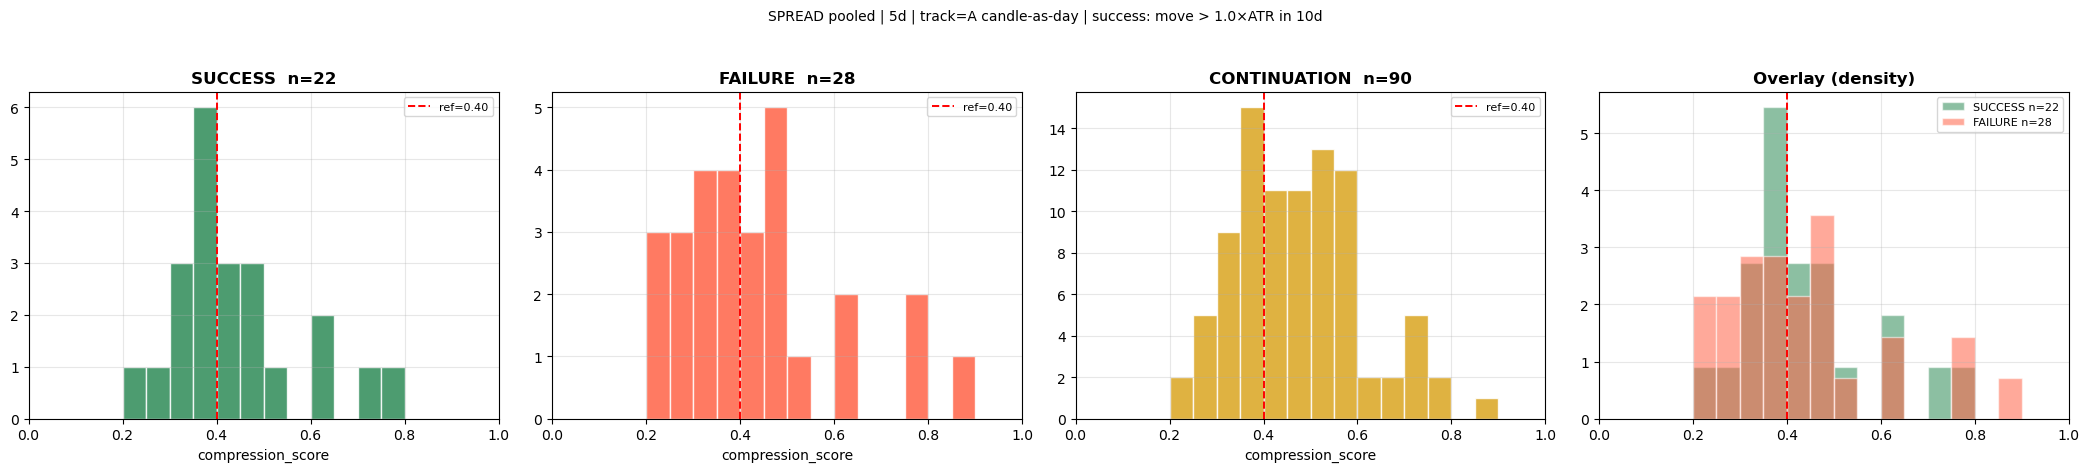


  JUMBO pooled | 5d | track=A candle-as-day | success: move > 1.0×ATR in 10d
  CONTINUATION=67  FAILURE=20  SUCCESS=11   | base rate (S/(S+F)) = 0.355

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,0,0,--
"[0.25, 0.3)",2,2,0,4,0.50
"[0.3, 0.35)",2,1,2,5,0.67
"[0.35, 0.4)",2,2,3,7,0.50
"[0.4, 0.45)",1,4,11,16,0.20



  Threshold sweep  | base=0.355  PR-AUC=0.262


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
1,0.050,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
2,0.100,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
3,0.150,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
4,0.200,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
5,0.250,31,0.355,"[0.290, 0.452]",1.000,0.524,—,1.000,11,20,0,0,False
6,0.300,27,0.333,"[0.276, 0.478]",0.818,0.474,-0.117,0.939,9,18,2,2,False
7,0.350,24,0.292,"[0.260, 0.429]",0.636,0.400,-0.244,0.822,7,17,4,3,False
8,0.400,20,0.250,"[0.204, 0.417]",0.455,0.323,-0.295,0.705,5,15,6,5,False
9,0.450,15,0.267,"[0.200, 0.441]",0.364,0.308,-0.178,0.752,4,11,7,9,False


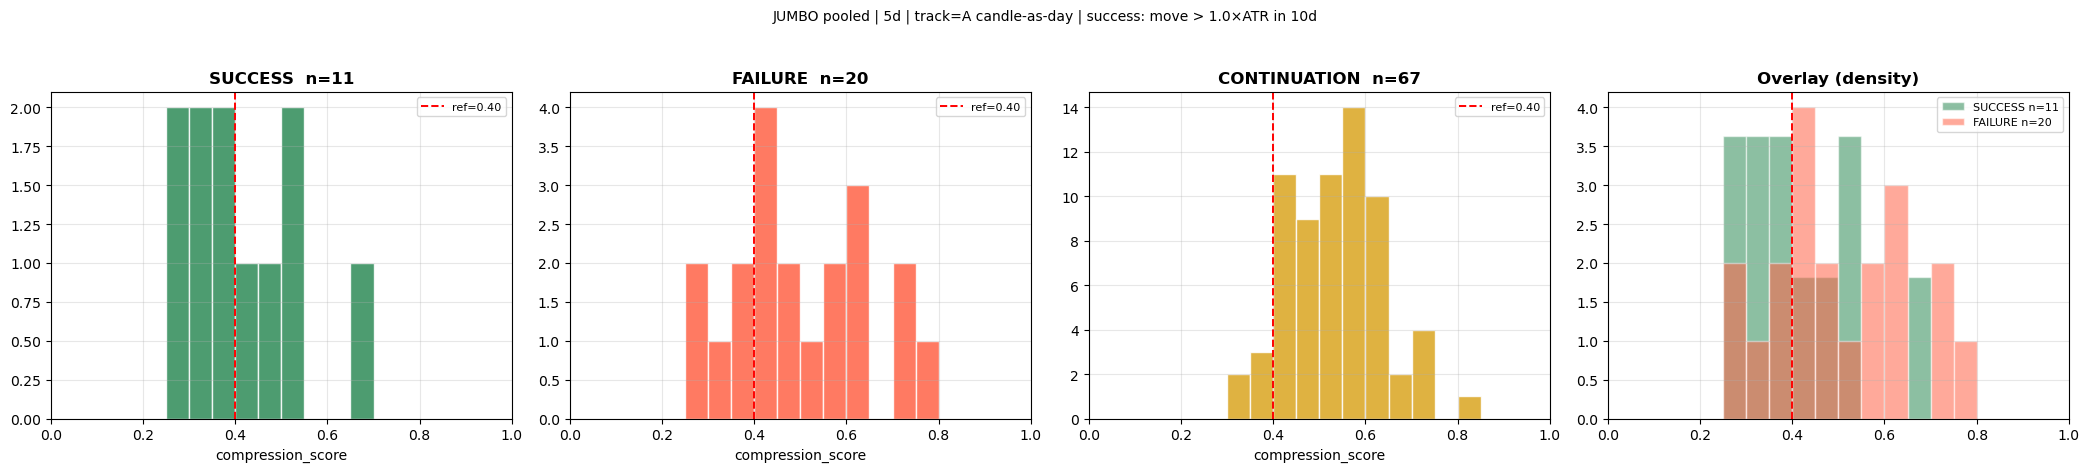


  SPREAD pooled | 2d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  SUCCESS=47  CONTINUATION=40  FAILURE=13   | base rate (S/(S+F)) = 0.783

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",1,0,0,1,1.00
"[0.2, 0.25)",1,1,0,2,0.50
"[0.25, 0.3)",5,1,2,8,0.83
"[0.3, 0.35)",6,0,4,10,1.00
"[0.35, 0.4)",5,2,6,13,0.71
"[0.4, 0.45)",7,1,4,12,0.88



  Threshold sweep  | base=0.783  PR-AUC=0.758


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,60,0.783,"[0.650, 0.883]",1.000,0.879,—,1.000,47,13,0,0,False
1,0.050,60,0.783,"[0.650, 0.883]",1.000,0.879,—,1.000,47,13,0,0,False
2,0.100,60,0.783,"[0.650, 0.883]",1.000,0.879,—,1.000,47,13,0,0,False
3,0.150,60,0.783,"[0.650, 0.883]",1.000,0.879,—,1.000,47,13,0,0,False
4,0.200,59,0.780,"[0.644, 0.878]",0.979,0.868,-0.068,0.995,46,13,1,0,False
5,0.250,57,0.789,"[0.664, 0.891]",0.957,0.865,0.065,1.008,45,12,2,1,False
6,0.300,51,0.784,"[0.612, 0.889]",0.851,0.816,0.006,1.001,40,11,7,2,False
7,0.350,45,0.756,"[0.596, 0.878]",0.723,0.739,-0.117,0.965,34,11,13,2,False
8,0.400,38,0.763,"[0.588, 0.926]",0.617,0.682,-0.064,0.974,29,9,18,4,False
9,0.450,30,0.733,"[0.543, 0.939]",0.468,0.571,-0.121,0.936,22,8,25,5,False


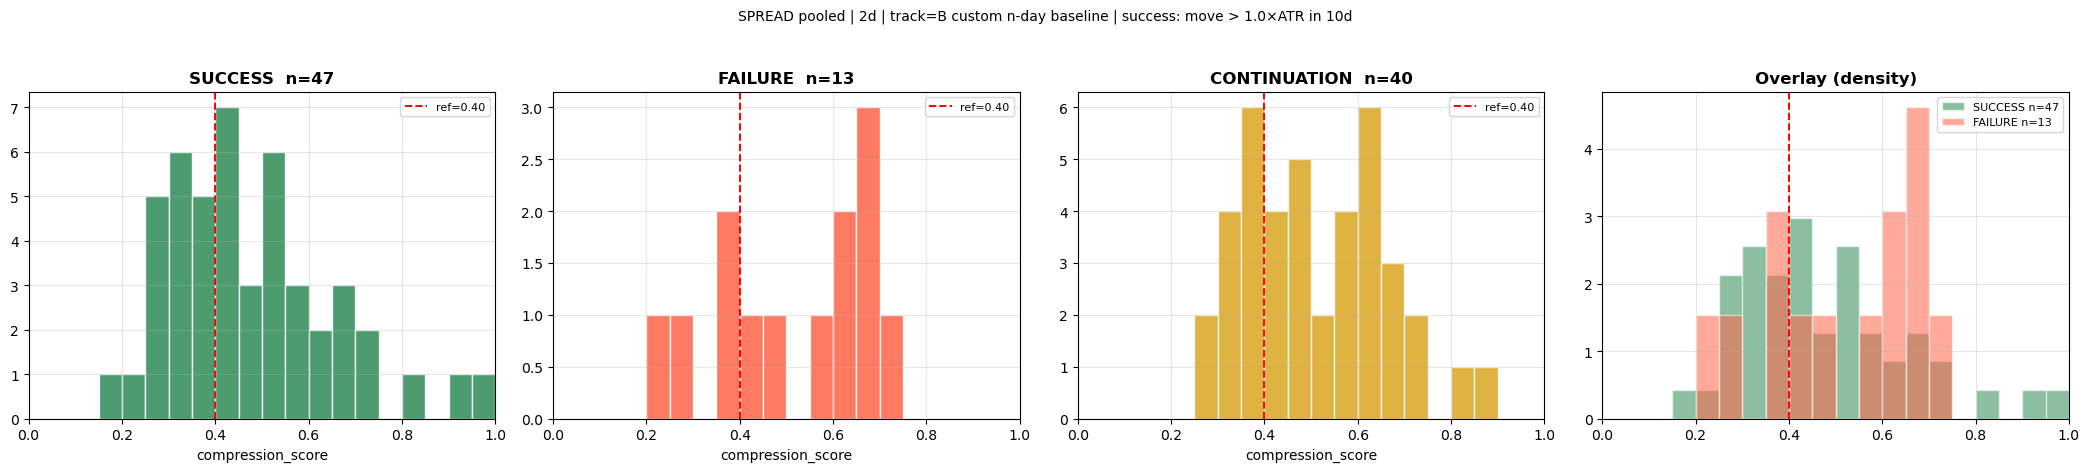


  JUMBO pooled | 2d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CONTINUATION=40  SUCCESS=29  FAILURE=3   | base rate (S/(S+F)) = 0.906

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,1,1,--
"[0.25, 0.3)",2,0,2,4,1.00
"[0.3, 0.35)",1,0,4,5,1.00
"[0.35, 0.4)",5,0,1,6,1.00
"[0.4, 0.45)",3,0,2,5,1.00



  Threshold sweep  | base=0.906  PR-AUC=0.907


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
1,0.050,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
2,0.100,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
3,0.150,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
4,0.200,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
5,0.250,32,0.906,"[0.875, 1.000]",1.000,0.951,—,1.000,29,3,0,0,False
6,0.300,30,0.900,"[0.867, 1.000]",0.931,0.915,-0.083,0.993,27,3,2,0,False
7,0.350,29,0.897,"[0.862, 1.000]",0.897,0.897,-0.103,0.989,26,3,3,0,False
8,0.400,24,0.875,"[0.826, 1.000]",0.724,0.792,-0.186,0.966,21,3,8,0,False
9,0.450,21,0.857,"[0.789, 1.000]",0.621,0.720,-0.233,0.946,18,3,11,0,False


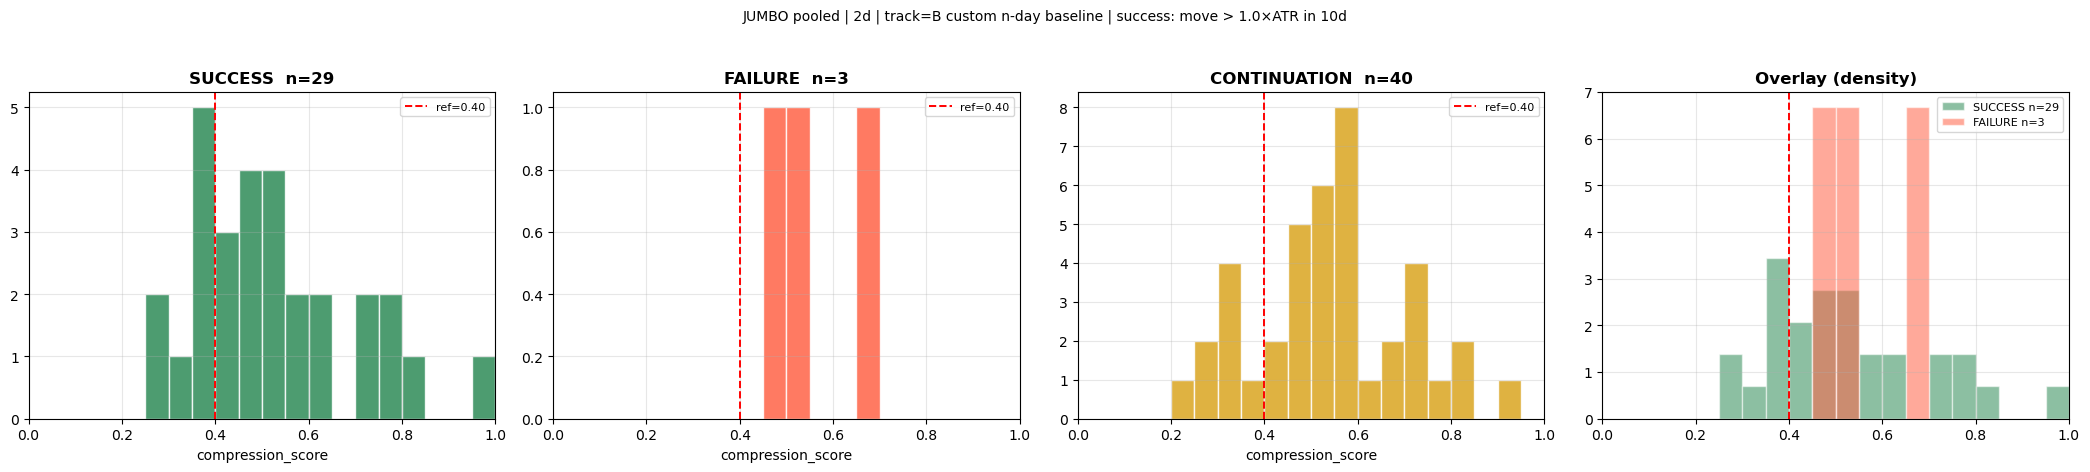


  SPREAD pooled | 3d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CONTINUATION=27  SUCCESS=20  FAILURE=14   | base rate (S/(S+F)) = 0.588

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,1,0,1,0.00
"[0.2, 0.25)",0,2,0,2,0.00
"[0.25, 0.3)",0,2,2,4,0.00
"[0.3, 0.35)",2,0,1,3,1.00
"[0.35, 0.4)",1,3,1,5,0.25
"[0.4, 0.45)",4,3,2,9,0.57



  Threshold sweep  | base=0.588  PR-AUC=0.820


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,34,0.588,"[0.353, 0.735]",1.000,0.741,—,1.000,20,14,0,0,False
1,0.050,34,0.588,"[0.353, 0.735]",1.000,0.741,—,1.000,20,14,0,0,False
2,0.100,34,0.588,"[0.353, 0.735]",1.000,0.741,—,1.000,20,14,0,0,False
3,0.150,34,0.588,"[0.353, 0.735]",1.000,0.741,—,1.000,20,14,0,0,False
4,0.200,33,0.606,"[0.387, 0.735]",1.000,0.755,0.208,1.030,20,13,0,1,False
5,0.250,31,0.645,"[0.435, 0.765]",1.000,0.784,0.372,1.097,20,11,0,3,False
6,0.300,29,0.690,"[0.441, 0.781]",1.000,0.816,0.496,1.172,20,9,0,5,False
7,0.350,27,0.667,"[0.400, 0.759]",0.900,0.766,0.313,1.133,18,9,2,5,False
8,0.400,23,0.739,"[0.456, 0.915]",0.850,0.791,0.443,1.257,17,6,3,8,False
9,0.450,16,0.812,"[0.600, 0.889]",0.650,0.722,0.430,1.381,13,3,7,11,False


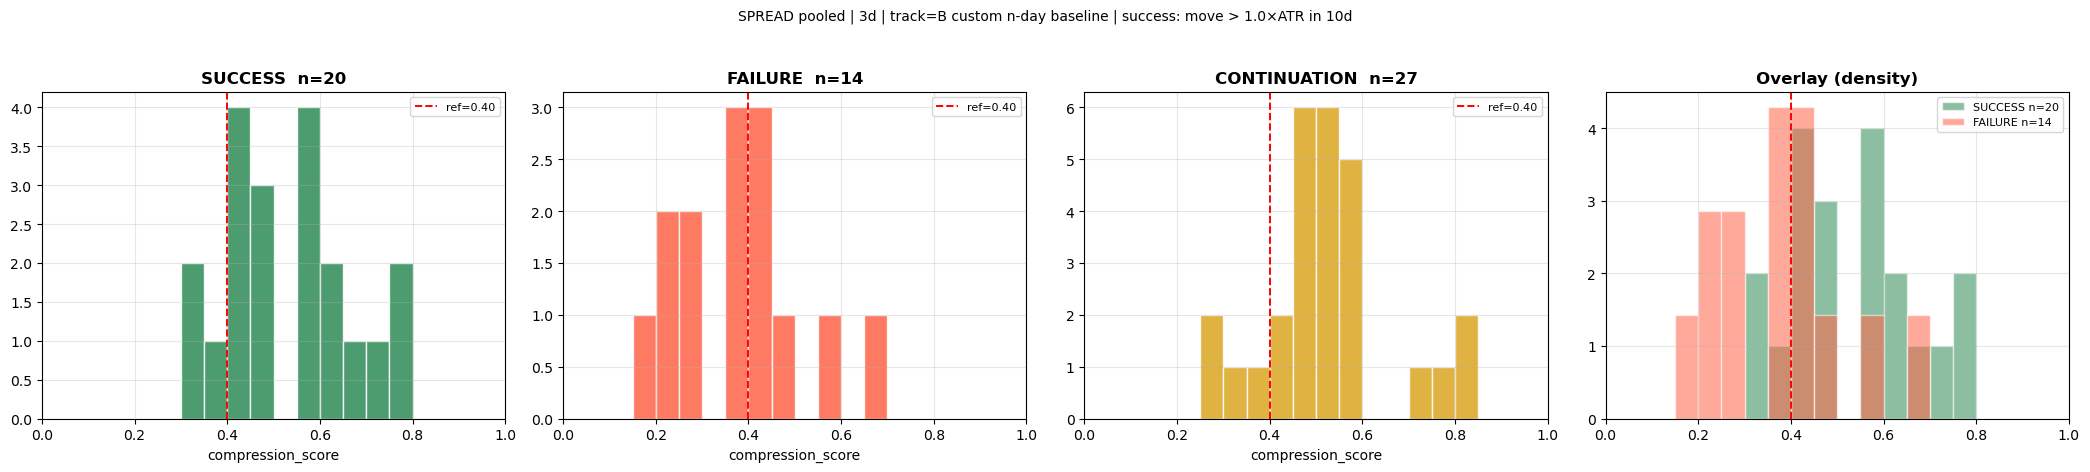


  JUMBO pooled | 3d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  SUCCESS=19  CONTINUATION=13  FAILURE=10   | base rate (S/(S+F)) = 0.655

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",1,0,0,1,1.00
"[0.25, 0.3)",4,2,0,6,0.67
"[0.3, 0.35)",1,1,0,2,0.50
"[0.35, 0.4)",2,1,1,4,0.67
"[0.4, 0.45)",3,0,1,4,1.00



  Threshold sweep  | base=0.655  PR-AUC=0.562


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,29,0.655,"[0.517, 0.793]",1.000,0.792,—,1.000,19,10,0,0,False
1,0.050,29,0.655,"[0.517, 0.793]",1.000,0.792,—,1.000,19,10,0,0,False
2,0.100,29,0.655,"[0.517, 0.793]",1.000,0.792,—,1.000,19,10,0,0,False
3,0.150,29,0.655,"[0.517, 0.793]",1.000,0.792,—,1.000,19,10,0,0,False
4,0.200,29,0.655,"[0.517, 0.793]",1.000,0.792,—,1.000,19,10,0,0,False
5,0.250,28,0.643,"[0.481, 0.793]",0.947,0.766,-0.137,0.981,18,10,1,0,False
6,0.300,22,0.636,"[0.452, 0.793]",0.737,0.683,-0.070,0.971,14,8,5,2,False
7,0.350,20,0.650,"[0.471, 0.833]",0.684,0.667,-0.016,0.992,13,7,6,3,False
8,0.400,17,0.647,"[0.471, 0.882]",0.579,0.611,-0.020,0.988,11,6,8,4,False
9,0.450,14,0.571,"[0.286, 0.846]",0.421,0.485,-0.170,0.872,8,6,11,4,False


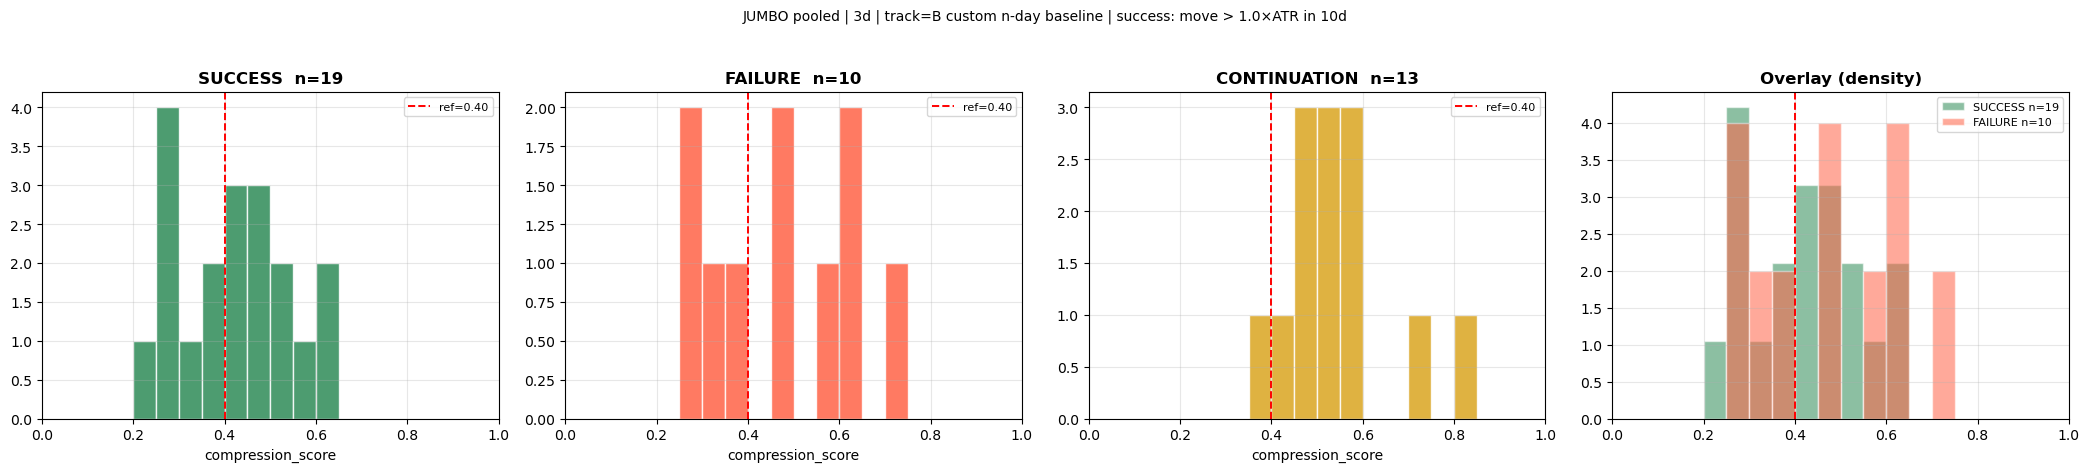


  SPREAD pooled | 5d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  FAILURE=11  CONTINUATION=10  SUCCESS=5   | base rate (S/(S+F)) = 0.312

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,1,1,--
"[0.25, 0.3)",0,0,0,0,--
"[0.3, 0.35)",1,3,0,4,0.25
"[0.35, 0.4)",0,0,0,0,--
"[0.4, 0.45)",1,4,1,6,0.20



  Threshold sweep  | base=0.312  PR-AUC=0.349


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
1,0.050,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
2,0.100,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
3,0.150,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
4,0.200,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
5,0.250,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
6,0.300,16,0.312,"[0.250, 0.375]",1.000,0.476,—,1.000,5,11,0,0,False
7,0.350,12,0.333,"[0.240, 0.462]",0.800,0.471,0.078,1.067,4,8,1,3,False
8,0.400,12,0.333,"[0.240, 0.462]",0.800,0.471,0.078,1.067,4,8,1,3,False
9,0.450,7,0.429,"[0.375, 0.800]",0.600,0.500,0.221,1.371,3,4,2,7,True


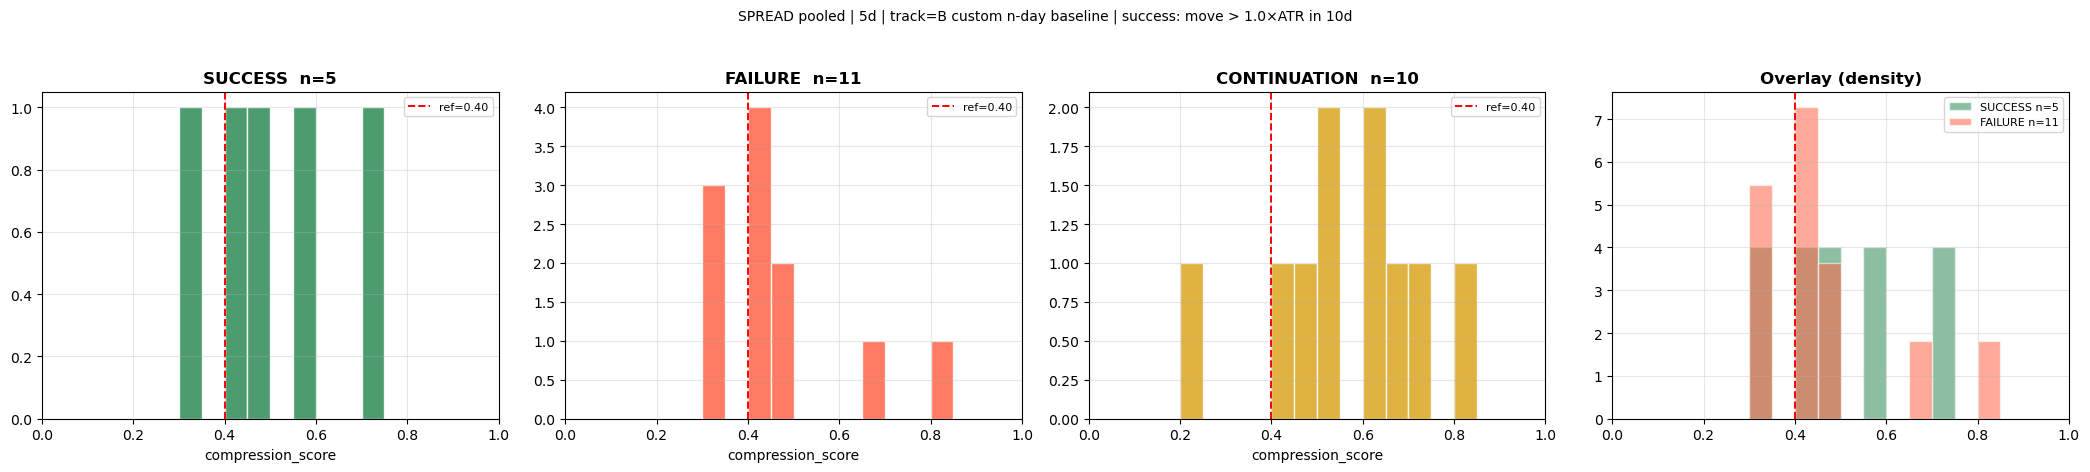


  JUMBO pooled | 5d | track=B custom n-day baseline | success: move > 1.0×ATR in 10d
  CONTINUATION=11  SUCCESS=3  FAILURE=3   | base rate (S/(S+F)) = 0.500

  Score-bucket distribution (0 -> 1):


outcome,SUCCESS,FAILURE,CONTINUATION,N,success_rate
bucket,,,,,
"[0.0, 0.05)",0,0,0,0,--
"[0.05, 0.1)",0,0,0,0,--
"[0.1, 0.15)",0,0,0,0,--
"[0.15, 0.2)",0,0,0,0,--
"[0.2, 0.25)",0,0,0,0,--
"[0.25, 0.3)",0,0,0,0,--
"[0.3, 0.35)",0,0,1,1,--
"[0.35, 0.4)",0,0,0,0,--
"[0.4, 0.45)",0,2,2,4,0.00



  Threshold sweep  | base=0.500  PR-AUC=1.000


,Threshold,N,Precision,Prec CI 95%,Recall,F1,MCC,Lift,TP,FP,FN,TN,Low N
0,0.000,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
1,0.050,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
2,0.100,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
3,0.150,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
4,0.200,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
5,0.250,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
6,0.300,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
7,0.350,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
8,0.400,6,0.500,"[0.500, 0.500]",1.000,0.667,—,1.000,3,3,0,0,True
9,0.450,4,0.750,"[0.750, 0.750]",1.000,0.857,0.707,1.500,3,1,0,2,True


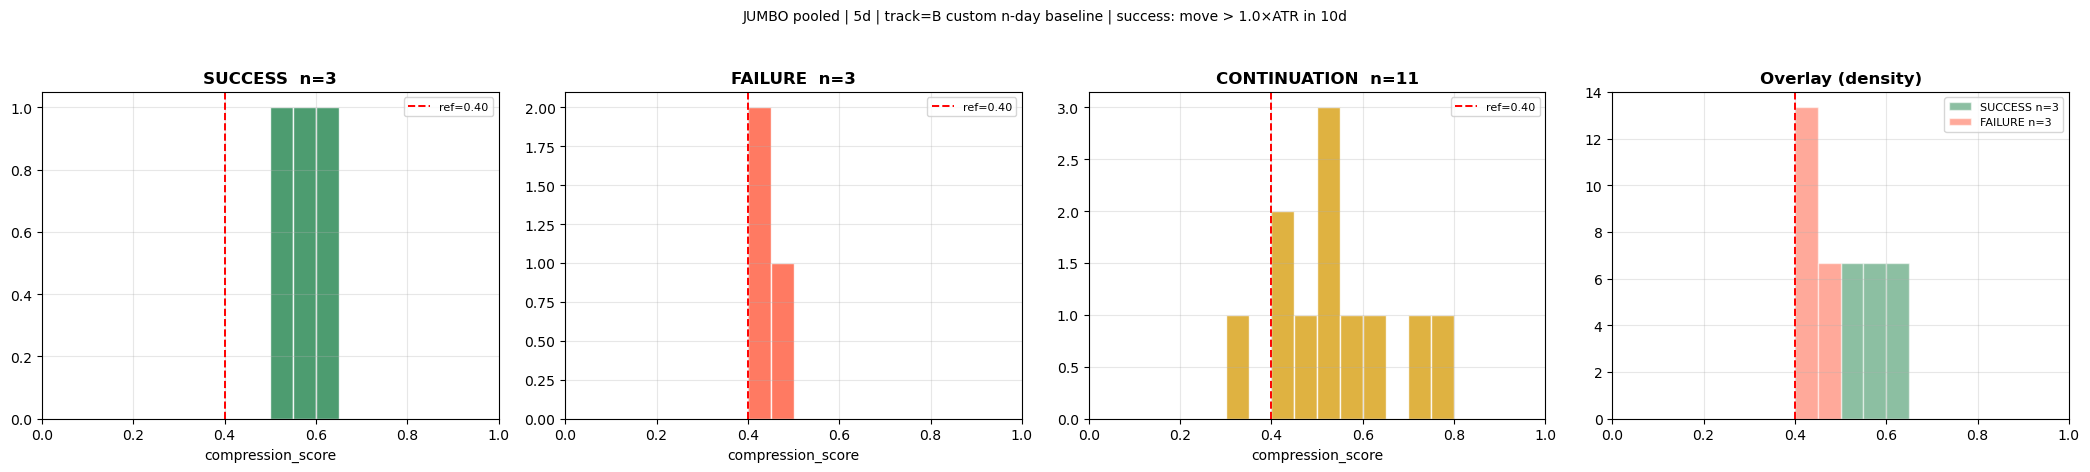


##############################################################################
  PER-INSTRUMENT SUMMARY
##############################################################################


,track,horizon,structure,instrument,signals,success,failure,continuation,censored,base_rate
0,candle,1d,spread,SMZ26-F27,26,16,0,10,0,1.000000
1,candle,1d,spread,SMF27-H27,23,13,1,9,0,0.928571
2,candle,1d,spread,SMH27-K27,20,14,2,4,0,0.875000
3,candle,1d,spread,SMK27-N27,25,18,0,7,0,1.000000
4,candle,1d,spread,SMN27-Q27,14,8,0,4,2,1.000000
...,...,...,...,...,...,...,...,...,...,...
62,custom,5d,spread,SMH27-K27,3,0,2,1,0,0.000000
63,custom,5d,spread,SMK27-N27,8,1,5,2,0,0.166667
64,custom,5d,jumbo,SMZ26-H27,12,2,2,8,0,0.500000
65,custom,5d,jumbo,SMZ26-K27,3,0,1,2,0,0.000000


In [6]:
res = run_compression_atr_analysis(
    product_code = "SM",
    horizons     = ["1d", "2d", "3d", "5d"],
    tracks       = ("candle", "custom"),
    months_back  = 6,
    front_n      = 5,
    k_atr        = 1.0,
)
# res["summary"], res["labeled"][("custom","3d","spread")], res["sweeps"][...]